# 00 · Veriyi tanı: İK meslekleri ve Claude kullanımı

**Amaç:** Analiz ya da model değil, yalnızca **veriyi anlamak**. İK filtresinden sonra elimizde ne
olduğunu, ne olmadığını ve nerelerde dikkatli olmamız gerektiğini görmek.

**Kaynak:** [Anthropic Economic Index](https://huggingface.co/datasets/Anthropic/EconomicIndex), Hugging Face, CC-BY.

| Dosya | Ne içeriyor | Düzey |
|---|---|---|
| `release_2025_02_10/onet_task_statements.csv` | O*NET görev tanımları (meslek → görevler) | görev |
| `labor_market_impacts/task_penetration.csv` | görev metni → `penetration` | görev |
| `labor_market_impacts/job_exposure.csv` | meslek kodu → `observed_exposure` | meslek |

## Tanımlar

> ⚠️ **README yok.** `labor_market_impacts` klasöründe README bulunmuyor; Hugging Face'teki
> dataset kartı da bu sütunları tanımlamıyor. Aşağıdaki tanımlar, verinin yayımlandığı makaleden
> alındı: Massenkoff & McCrory (Mart 2026), *Labor market impacts of AI: A new measure and early evidence*,
> <https://www.anthropic.com/research/labor-market-impacts>. Makalede "penetration" kelimesi geçmiyor;
> makale aynı kavrama **coverage (kapsama)** diyor. Sütunla makaledeki terimi eşleştiren biziz.

**`penetration` (görev düzeyi, 0–1):** Bir görevin Claude'un iş amaçlı kullanımında ne ölçüde
"kapsandığı". Bir LLM'in teorik olarak hızlandırabileceği bir görev (Eloundou vd. 2023), Claude
trafiğinde **yeterli iş amaçlı kullanım** görmüşse kapsanmış sayılır. Tam otomasyon şeklindeki
kullanım tam ağırlık alır, destekleyici (augmentative) kullanım yarım ağırlık alır. Birbirine çok
benzeyen O*NET görevlerinde kullanım sayıları aralarında bölünür.

**`observed_exposure` (meslek düzeyi, 0–1):** Görev düzeyindeki kapsama değerlerinin meslek düzeyinde
ortalaması. Ortalama, **her göreve harcanan zaman payıyla ağırlıklıdır**. Bu zaman payları elimizdeki
dosyalarda yok.

### 0 ne demek: "kullanım yok" mu, "gözlem yok" mu?

**Gözlem yok (eşiğin altında).** Makaleden: *"30% of workers have zero coverage, as their tasks
appeared too infrequently in our data to meet the minimum threshold."* Yani 0, "bu görevde yapay
zekâ hiç kullanılmıyor" demek değil. "Claude örnekleminde bu görev, minimum eşiği geçecek kadar sık
görülmedi" demek. Eşiğin sayısal değeri yayımlanmamış. Ayrıca LLM'in teorik olarak hızlandıramadığı
görevler (β = 0) tanım gereği kapsanmaz, onlar da 0 olabilir. Bu iki tür 0'ı veriden **ayırt edemiyoruz**.

**Bu notebook boyunca:** 0'ı "düşük/eşik altı" diye okuyun, "yok" diye değil. Eşleşmeyen görevler ise
**0 değil, boş (NaN)** kalır.

## Veri sözlüğü: veri seti ne, sütunlar ne anlama geliyor?

### Büyük resim

Üç tablo var ve birbirine şöyle bağlanıyor:

```
job_exposure (meslek)  ──occ_code──▶  onet_task_statements (meslek → görevler)  ──görev metni──▶  task_penetration (görev → puan)
   "İK Uzmanı: 0,40"                    "İK Uzmanı'nın 25 görevi"                                   "Bu görev Claude'da görülüyor mu?"
```

- **O*NET**, ABD Çalışma Bakanlığı'nın meslek veritabanı. Her mesleği, o meslekteki kişilerin yaptığı
  somut görevlere böler. Bu görev listeleri Anthropic'e değil O*NET'e ait.
- **Anthropic**, Claude'daki iş amaçlı konuşmaları bu O*NET görevleriyle eşleştirip her göreve ve
  mesleğe bir puan vermiş.

---

### 1) `onet_task_statements.csv`: "Hangi meslek hangi görevleri yapar?"
19.530 satır, 974 ayrıntılı meslek. **Her satır bir meslekteki bir görev.**

| Sütun | Anlamı | Örnek |
|---|---|---|
| `O*NET-SOC Code` | Ayrıntılı meslek kodu. İlk 7 karakter ana meslek, `.00`/`.01`/`.02` alt meslek | `13-1071.00` |
| `Title` | Mesleğin İngilizce adı | Human Resources Specialists |
| `Task ID` | Görevin O*NET'teki benzersiz numarası | `18861` |
| `Task` | Görevin kendisi, tek cümle | "Interpret and explain human resources policies, procedures, laws, standards, or regulations." (İK politikalarını, prosedürlerini ve yasalarını yorumla ve açıkla) |
| `Task Type` | **Core** = mesleğin asıl, önemli görevi. **Supplemental** = ek, daha az merkezi görev. Boş = sınıflandırılmamış | `Core` |
| `Incumbents Responding` | O*NET anketinde bu görevi değerlendiren, o meslekte çalışan kişi sayısı (19–349) | `124` |
| `Date` | Görev bilgisinin O*NET'te güncellendiği ay/yıl (2003–2015) | `07/2012` |
| `Domain Source` | Bilgi kimden geldi: **Incumbent** = mesleği yapan çalışanlar, **Occupational Expert** = meslek uzmanları, **Analyst** = O*NET analistleri | `Incumbent` |

Not: `Task Type` ve `Incumbents Responding` sütunlarının boş olduğu 658 satırın **tamamı** `Analyst`
kaynaklı. Analistlerin yazdığı görevler çalışanlara sorulmadığı için Core/Supplemental olarak
sınıflandırılmamış. İK görevlerinde bu durum yok.

---

### 2) `task_penetration.csv`: "Bu görev Claude'da ne kadar görülüyor?"
17.998 satır. **Her satır bir görev metni.**

| Sütun | Anlamı | Örnek |
|---|---|---|
| `task` | O*NET görev metni. Task ID yok, bu yüzden görev tablosuna **metin üzerinden** bağlanıyor | "Accept music requests from event guests." |
| `penetration` | Görevin Claude'un iş kullanımında kapsanma puanı, 0–1 | `0.0` veya `0.91` |

`penetration` nasıl okunur:
- **0**: Görev Claude'da **eşiği geçecek kadar sık görülmedi** (%92,5'i böyle). "Hiç kullanılmıyor" demek değil.
- **0,5–1**: Yeterince görüldü. Claude işi kendisi yapıyorsa (otomasyon) tam puan, yardımcı oluyorsa
  (destek) yarım puan. 1'e yakınsa kullanım ağırlıklı olarak otomasyon.
- 0 ile 0,5 arasında değer yok. Bu yüzden puanı bir ölçek değil, daha çok **"görüldü / görülmedi" bayrağı** gibi okuyun.

---

### 3) `job_exposure.csv`: "Bu meslek bir bütün olarak ne kadar etkileniyor?"
756 satır. **Her satır bir meslek.**

| Sütun | Anlamı | Örnek |
|---|---|---|
| `occ_code` | Meslek kodu, **`.00` olmadan** (görev tablosundaki kodun ilk 7 karakteri) | `13-1071` |
| `title` | Mesleğin İngilizce adı | Human Resources Specialists |
| `observed_exposure` | Mesleğin "gözlenen maruziyeti", 0–1. Görevlerin penetration puanlarının, **her göreve harcanan zamana göre ağırlıklı** ortalaması | `0.4034` |

`observed_exposure` nasıl okunur: İK Uzmanı = 0,40 → kabaca "bu mesleğin iş zamanının yaklaşık %40'ına
denk gelen görevler Claude'da iş amaçlı görülüyor". **0** yine "eşik altı" demek (mesleklerin %54'ü).
Bu bir "işini kaybetme riski" skoru **değil**, yalnızca gözlenen kullanımı ölçüyor.

---

### Bu veride OLMAYANLAR
- Kaç kişinin çalıştığı, maaşlar (başka dosyalarda var, burada kullanılmıyor)
- Göreve harcanan zaman payları (meslek skorunun hesabında kullanılmış ama paylaşılmamış)
- Otomasyon ve destek ayrımı (tek puanda birleşmiş)
- Zaman içindeki değişim (tek bir kesit)
- Claude dışındaki yapay zekâ araçları

## 1 · Kurulum

İlk kez çalıştırıyorsanız proje kökünde (PowerShell):

```powershell
python -m venv .venv
.\.venv\Scripts\Activate.ps1
pip install -r requirements.txt
jupyter notebook notebooks/00_veriyi_tani.ipynb
```

**Bu hücre ne yapıyor:** Paketleri yüklüyor, `SEED = 42`'yi sabitliyor, klasör yollarını tanımlıyor ve üç
yardımcı fonksiyon tanımlıyor:
- `log()`: satır sayısını değiştirebilen her adımda öncesini ve sonrasını yazdırır.
- `oku()`: dosyayı okur ve beklenen sütunlar gerçekten var mı diye `assert` ile kontrol eder.
  Dosya `data/` içinde varsa oradan, yoksa doğrudan Hugging Face'ten okur.
- `ozetle()`: shape, sütunlar, eksik değerler ve ilk 5 satırı gösterir.

**Neye bakın:** Çıktıda pandas sürümü ve proje kökü doğru mu? Notebook `notebooks/` klasöründen
çalıştırılmalıdır, aksi halde `assert` hata verir.

In [1]:
from pathlib import Path
import difflib
import random
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent
assert (ROOT / "CLAUDE.md").exists(), f"Notebook notebooks/ klasöründen çalıştırılmalı; şu anki klasör: {Path.cwd()}"
ROOT = ROOT.resolve()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
TABLE_DIR = ROOT / "reports" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://huggingface.co/datasets/Anthropic/EconomicIndex/resolve/main/"

print("Python    :", sys.version.split()[0])
print("pandas    :", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Proje kökü:", ROOT.name)


def log(adim, once, sonra):
    print(f"[{adim}] önce: {once:,} satır → sonra: {sonra:,} satır (fark: {sonra - once:+,})")


def oku(hf_yolu, beklenen_sutunlar, **kwargs):
    yerel = DATA_DIR / Path(hf_yolu).name
    kaynak = yerel if yerel.exists() else BASE_URL + hf_yolu
    print("Kaynak:", kaynak)
    df = pd.read_csv(kaynak, **kwargs)
    eksik = set(beklenen_sutunlar) - set(df.columns)
    assert not eksik, f"{hf_yolu}: beklenen sütunlar yok: {eksik}. Var olanlar: {list(df.columns)}"
    return df


def ozetle(df):
    print("shape   :", df.shape)
    print("sütunlar:", list(df.columns))
    print("\nEksik değer sayısı:")
    print(df.isna().sum().to_string())
    display(df.head())

Python    : 3.14.3
pandas    : 3.1.1
matplotlib: 3.11.2
Proje kökü: hr-ai-exposure-analysis


## 2 · Dosyaları oku

### 2.1 · `onet_task_statements.csv`: O*NET görevleri

**Bu hücre ne yapıyor:** Görev tablosunu okuyor, gerekli sütunları kontrol ediyor ve özetliyor.
Ardından `Task Type` değerlerini sayıyor ve meslek kodunun biçimini kontrol ediyor.

**Neye bakın:**
- Kod biçimi `13-1071.00`. Sondaki iki hane O*NET'in alt meslek kodudur, her zaman `.00` değildir.
- `Task Type` sütununda boş değerler var. Bu görevlerin Core mu Supplemental mı olduğu bilinmiyor.
- Satır başına tek görev var, ama aynı görev metni birden fazla meslekte geçebilir.

In [2]:
ts = oku("release_2025_02_10/onet_task_statements.csv",
         ["O*NET-SOC Code", "Title", "Task ID", "Task", "Task Type"])
ozetle(ts)

print("\nTask Type dağılımı (boşlar dahil):")
print(ts["Task Type"].value_counts(dropna=False).to_string())

assert ts["O*NET-SOC Code"].str.fullmatch(r"\d{2}-\d{4}\.\d{2}").all(), "Beklenmeyen kod biçimi var"
print("\nKod son ekleri (ilk 10):")
print(ts["O*NET-SOC Code"].str[-3:].value_counts().head(10).to_string())

Kaynak: https://huggingface.co/datasets/Anthropic/EconomicIndex/resolve/main/release_2025_02_10/onet_task_statements.csv


shape   : (19530, 8)
sütunlar: ['O*NET-SOC Code', 'Title', 'Task ID', 'Task', 'Task Type', 'Incumbents Responding', 'Date', 'Domain Source']

Eksik değer sayısı:
O*NET-SOC Code             0
Title                      0
Task ID                    0
Task                       0
Task Type                658
Incumbents Responding    658
Date                       0
Domain Source              0


,O*NET-SOC Code,Title,Task ID,Task,Task Type,Incumbents Responding,Date,Domain Source
0,11-1011.00,Chief Executives,8823,"Direct or coordinate an organization's financial or budget activities to fund operations, maximize investments, or increase efficiency.",Core,87.0,07/2014,Incumbent
1,11-1011.00,Chief Executives,8831,Appoint department heads or managers and assign or delegate responsibilities to them.,Core,87.0,07/2014,Incumbent
2,11-1011.00,Chief Executives,8825,Analyze operations to evaluate performance of a company or its staff in meeting objectives or to determine areas of potential cost reduc...,Core,87.0,07/2014,Incumbent
3,11-1011.00,Chief Executives,8826,"Direct, plan, or implement policies, objectives, or activities of organizations or businesses to ensure continuing operations, to maximi...",Core,87.0,07/2014,Incumbent
4,11-1011.00,Chief Executives,8827,"Prepare budgets for approval, including those for funding or implementation of programs.",Core,87.0,07/2014,Incumbent



Task Type dağılımı (boşlar dahil):
Task Type
Core            13487
Supplemental     5385
NaN               658

Kod son ekleri (ilk 10):
O*NET-SOC Code
.00    13902
.01     2098
.02     1153
.03      655
.04      342
.07      316
.06      288
.05      246
.08      152
.10      112


### 2.2 · `task_penetration.csv`: görev metni → penetration

**Bu hücre ne yapıyor:** Penetration tablosunu okuyor, değerlerin 0–1 aralığında olduğunu doğruluyor
ve kaç görevin 0 olduğunu sayıyor.

**Neye bakın:**
- Bu tabloda **görev kimliği (Task ID) yok**, yalnızca görev metni var. Görev tablosuyla birleştirme
  metin üzerinden yapılmak zorunda (bkz. Bölüm 5).
- Görevlerin büyük çoğunluğu 0. Bölüm 0'daki uyarıyı hatırlayın: 0, "eşiğin altında" demek.
- **Pozitif değerlerin minimumuna bakın.** Bu veri sürümünde en küçük pozitif değer 0,50. 0 ile 0,50
  arasında hiç değer yok. Yani penetration sürekli bir "kullanım yoğunluğu" gibi değil, daha çok
  "eşiği geçti mi" bayrağı (+ otomasyon/destek ağırlığı) gibi davranıyor. 0,9 ile 0,8 arasındaki
  fark, 0 ile 0,8 arasındaki farkla aynı türden bir fark değil.

In [3]:
tp = oku("labor_market_impacts/task_penetration.csv", ["task", "penetration"])
ozetle(tp)

assert tp["penetration"].between(0, 1).all(), "penetration 0–1 aralığı dışında değer içeriyor"
sifir = (tp["penetration"] == 0).sum()
print(f"\npenetration = 0 : {sifir:,} / {len(tp):,} görev ({sifir / len(tp):.1%})")
print(f"penetration > 0 : {len(tp) - sifir:,} görev")
print("\npenetration > 0 olanların dağılımı:")
print(tp.loc[tp["penetration"] > 0, "penetration"].describe().round(3).to_string())

Kaynak: https://huggingface.co/datasets/Anthropic/EconomicIndex/resolve/main/labor_market_impacts/task_penetration.csv


shape   : (17998, 2)
sütunlar: ['task', 'penetration']

Eksik değer sayısı:
task           0
penetration    0


,task,penetration
0,"Accept and check containers of mail from large volume mailers, couriers, and contractors.",0.0
1,"Accept and check containers of mail or parcels from large volume mailers, couriers, and contractors.",0.0
2,Accept credit applications and verify credit references to provide check-cashing authorization or to establish house credit accounts.,0.0
3,Accept music requests from event guests.,0.0
4,"Accept payment from customers, and make change as necessary.",0.0



penetration = 0 : 16,644 / 17,998 görev (92.5%)
penetration > 0 : 1,354 görev

penetration > 0 olanların dağılımı:
count    1354.000
mean        0.887
std         0.098
min         0.500
25%         0.819
50%         0.910
75%         0.973
max         1.000


### 2.3 · `job_exposure.csv`: meslek → observed_exposure

**Bu hücre ne yapıyor:** Meslek tablosunu okuyor. `occ_code` metin olarak okunuyor ki baştaki
sıfırlar kaybolmasın. Her kodun tek satır olduğunu doğruluyor.

**Neye bakın:** Kod biçimi `13-1071`, yani `.00` yok. Kaç meslekte değer 0?

In [4]:
je = oku("labor_market_impacts/job_exposure.csv", ["occ_code", "title", "observed_exposure"],
         dtype={"occ_code": str})
ozetle(je)

assert je["occ_code"].is_unique, "job_exposure'da tekrar eden meslek kodu var"
assert je["occ_code"].str.fullmatch(r"\d{2}-\d{4}").all(), "Beklenmeyen kod biçimi var"
assert je["observed_exposure"].between(0, 1).all()

sifir = (je["observed_exposure"] == 0).sum()
print(f"\nobserved_exposure = 0 : {sifir:,} / {len(je):,} meslek ({sifir / len(je):.1%})")

Kaynak: https://huggingface.co/datasets/Anthropic/EconomicIndex/resolve/main/labor_market_impacts/job_exposure.csv


shape   : (756, 3)
sütunlar: ['occ_code', 'title', 'observed_exposure']

Eksik değer sayısı:
occ_code             0
title                0
observed_exposure    0


,occ_code,title,observed_exposure
0,11-1011,Chief Executives,0.0333
1,11-1021,General and Operations Managers,0.1378
2,11-1031,Legislators,0.0000
3,11-2011,Advertising and Promotions Managers,0.1731
4,11-2021,Marketing Managers,0.3195



observed_exposure = 0 : 411 / 756 meslek (54.4%)


## 3 · İK filtresi: meslek tablosu

**Bu hücre ne yapıyor:** 7 İK mesleğini ve 2 karşılaştırma mesleğini Türkçe adlarıyla tanımlıyor. Her
kodun `job_exposure`'da gerçekten bulunduğunu `assert` ile kontrol ediyor. Ardından tabloyu
`observed_exposure`'a göre büyükten küçüğe sıralıyor.

**Neye bakın:**
- **İK Müdürü ve Ücret ve Yan Haklar Müdürü 0.** Bu "yapay zekâ bu mesleklere dokunmuyor" demek değil,
  "Claude örnekleminde bu mesleklerin görevleri eşiği geçecek kadar görülmedi" demek.
- Aynı alandaki uzman ve asistan rolleri ise yüksek. Müdür ve uzman arasındaki bu fark, ileride
  incelenmeye değer bir soru (bkz. Bölüm 10).

In [5]:
MESLEKLER = pd.DataFrame(
    [
        ("11-3121", "İK Müdürü", "İK"),
        ("11-3111", "Ücret ve Yan Haklar Müdürü", "İK"),
        ("13-1071", "İK Uzmanı", "İK"),
        ("13-1141", "Ücret, Yan Haklar ve İş Analizi Uzmanı", "İK"),
        ("13-1151", "Eğitim ve Geliştirme Uzmanı", "İK"),
        ("43-3051", "Bordro ve Puantaj Memuru", "İK"),
        ("43-4161", "İK Asistanı", "İK"),
        ("13-2011", "Muhasebeci", "Karşılaştırma"),
        ("43-3031", "Muhasebe Memuru", "Karşılaştırma"),
    ],
    columns=["occ_code", "ad_tr", "grup"],
)
IK_KODLARI = MESLEKLER.loc[MESLEKLER["grup"] == "İK", "occ_code"].tolist()

bulunamayan = set(MESLEKLER["occ_code"]) - set(je["occ_code"])
assert not bulunamayan, f"job_exposure'da olmayan kodlar: {bulunamayan}"

once = len(je)
meslek = (
    MESLEKLER.merge(je, on="occ_code", how="left", validate="one_to_one")
    .rename(columns={"title": "ad_en"})
    [["occ_code", "ad_tr", "ad_en", "grup", "observed_exposure"]]
    .sort_values("observed_exposure", ascending=False)
    .reset_index(drop=True)
)
log("job_exposure → 9 meslek", once, len(meslek))
assert len(meslek) == len(MESLEKLER)

display(meslek)
print("observed_exposure = 0 olan meslekler:",
      meslek.loc[meslek["observed_exposure"] == 0, "ad_tr"].tolist())

[job_exposure → 9 meslek] önce: 756 satır → sonra: 9 satır (fark: -747)


,occ_code,ad_tr,ad_en,grup,observed_exposure
0,43-4161,İK Asistanı,"Human Resources Assistants, Except Payroll and Timekeeping",İK,0.4046
1,13-1071,İK Uzmanı,Human Resources Specialists,İK,0.4034
2,13-2011,Muhasebeci,Accountants and Auditors,Karşılaştırma,0.3478
3,43-3031,Muhasebe Memuru,"Bookkeeping, Accounting, and Auditing Clerks",Karşılaştırma,0.3104
4,13-1151,Eğitim ve Geliştirme Uzmanı,Training and Development Specialists,İK,0.2793
5,13-1141,"Ücret, Yan Haklar ve İş Analizi Uzmanı","Compensation, Benefits, and Job Analysis Specialists",İK,0.0649
6,43-3051,Bordro ve Puantaj Memuru,Payroll and Timekeeping Clerks,İK,0.0487
7,11-3121,İK Müdürü,Human Resources Managers,İK,0.0000
8,11-3111,Ücret ve Yan Haklar Müdürü,Compensation and Benefits Managers,İK,0.0000


observed_exposure = 0 olan meslekler: ['İK Müdürü', 'Ücret ve Yan Haklar Müdürü']


## 4 · Her İK mesleğinin görev listesi

### 4.1 · Kodları eşleştir

**Bu hücre ne yapıyor:** Görev tablosuna, kodun **ilk 7 karakterinden** bir `occ_code` sütunu ekliyor
(`13-1071.00` → `13-1071`). Ardından 9 mesleğe ait görevleri filtreliyor ve hangi ayrıntılı
O*NET kodlarının hangi meslek koduna düştüğünü gösteriyor.

**Neye bakın:** Neden `.00` kırpmak yerine ilk 7 karakter? **Muhasebeci (13-2011) için `.00` kodu yok**,
yalnızca `13-2011.01` (Muhasebeci) ve `13-2011.02` (Denetçi) var. `.00` kırpmak bu mesleği sessizce
kaybederdi. Aşağıdaki tabloda her meslek kodunun altında hangi ayrıntılı kodların toplandığına bakın.

In [6]:
ts = ts.assign(occ_code=ts["O*NET-SOC Code"].str[:7])

once = len(ts)
secili = ts[ts["occ_code"].isin(MESLEKLER["occ_code"])]
log("görevler → 9 meslek", once, len(secili))

bulunamayan = set(MESLEKLER["occ_code"]) - set(secili["occ_code"])
assert not bulunamayan, f"Görev tablosunda olmayan kodlar: {bulunamayan}"
assert not secili.duplicated(["O*NET-SOC Code", "Task ID"]).any(), "Aynı meslekte tekrar eden Task ID var"

print("\nMeslek kodu → ayrıntılı O*NET kodları ve görev sayıları:")
display(secili.groupby(["occ_code", "O*NET-SOC Code", "Title"]).size().rename("gorev_sayisi").reset_index())

[görevler → 9 meslek] önce: 19,530 satır → sonra: 222 satır (fark: -19,308)

Meslek kodu → ayrıntılı O*NET kodları ve görev sayıları:


,occ_code,O*NET-SOC Code,Title,gorev_sayisi
0,11-3111,11-3111.00,Compensation and Benefits Managers,24
1,11-3121,11-3121.00,Human Resources Managers,26
2,13-1071,13-1071.00,Human Resources Specialists,25
3,13-1141,13-1141.00,"Compensation, Benefits, and Job Analysis Specialists",24
4,13-1151,13-1151.00,Training and Development Specialists,20
5,13-2011,13-2011.01,Accountants,16
6,13-2011,13-2011.02,Auditors,20
7,43-3031,43-3031.00,"Bookkeeping, Accounting, and Auditing Clerks",30
8,43-3051,43-3051.00,Payroll and Timekeeping Clerks,19
9,43-4161,43-4161.00,"Human Resources Assistants, Except Payroll and Timekeeping",18


### 4.2 · Yalnızca İK görevleri

**Bu hücre ne yapıyor:** 7 İK mesleğinin görevlerini ayırıyor. Türkçe ve İngilizce meslek adlarını
ekliyor. Boş `Task Type` değerlerini silmiyor, **"Belirtilmemiş"** olarak etiketliyor (ham sütun
olduğu gibi kalıyor). Son olarak meslek × görev türü sayım tablosunu gösteriyor.

**Neye bakın:** Core görevler mesleğin asıl işi, Supplemental görevler ek işler. Her meslekte ikisinin
oranı nasıl?

In [7]:
once = len(secili)
ik_gorev = (
    secili[secili["occ_code"].isin(IK_KODLARI)]
    .merge(meslek[["occ_code", "ad_tr", "ad_en", "observed_exposure"]], on="occ_code",
           how="left", validate="many_to_one")
)
log("9 meslek → 7 İK mesleği", once, len(ik_gorev))

ik_gorev = ik_gorev.assign(gorev_turu=ik_gorev["Task Type"].fillna("Belirtilmemiş"))
print("Task Type boş olan İK görevi:", ik_gorev["Task Type"].isna().sum())

display(pd.crosstab(ik_gorev["ad_tr"], ik_gorev["gorev_turu"], margins=True, margins_name="Toplam"))

[9 meslek → 7 İK mesleği] önce: 222 satır → sonra: 156 satır (fark: -66)
Task Type boş olan İK görevi: 0


gorev_turu,Core,Supplemental,Toplam
ad_tr,,,
Bordro ve Puantaj Memuru,14,5,19
Eğitim ve Geliştirme Uzmanı,17,3,20
Ücret ve Yan Haklar Müdürü,15,9,24
"Ücret, Yan Haklar ve İş Analizi Uzmanı",12,12,24
İK Asistanı,7,11,18
İK Müdürü,21,5,26
İK Uzmanı,20,5,25
Toplam,106,50,156


### 4.3 · Meslek meslek görev listeleri

**Bu hücre ne yapıyor:** Her İK mesleği için görevleri listeliyor: önce Core, sonra Supplemental.

**Neye bakın:** Görevleri okuyun. Hangileri metin, belge veya veri işi; hangileri insanlarla yüz yüze iş?
Bu sezgiyi Bölüm 6'daki penetration değerleriyle karşılaştırın.

In [8]:
for kod in IK_KODLARI:
    g = ik_gorev[ik_gorev["occ_code"] == kod].sort_values(["gorev_turu", "Task ID"])
    print(f"\n■ {kod} · {g['ad_tr'].iloc[0]} ({g['ad_en'].iloc[0]}): {len(g)} görev")
    display(g[["Task ID", "gorev_turu", "Task"]].reset_index(drop=True))


■ 11-3121 · İK Müdürü (Human Resources Managers): 26 görev


,Task ID,gorev_turu,Task
0,982,Core,"Administer compensation, benefits and performance management systems, and safety and recreation programs."
1,983,Core,"Identify staff vacancies and recruit, interview and select applicants."
2,984,Core,"Allocate human resources, ensuring appropriate matches between personnel."
3,985,Core,"Provide current and prospective employees with information about policies, job duties, working conditions, wages, opportunities for prom..."
4,986,Core,"Perform difficult staffing duties, including dealing with understaffing, refereeing disputes, firing employees, and administering discip..."
5,987,Core,"Advise managers on organizational policy matters such as equal employment opportunity and sexual harassment, and recommend needed changes."
6,988,Core,Analyze and modify compensation and benefits policies to establish competitive programs and ensure compliance with legal requirements.
7,989,Core,Plan and conduct new employee orientation to foster positive attitude toward organizational objectives.
8,990,Core,"Serve as a link between management and employees by handling questions, interpreting and administering contracts and helping resolve wor..."
9,991,Core,"Plan, direct, supervise, and coordinate work activities of subordinates and staff relating to employment, compensation, labor relations,..."



■ 11-3111 · Ücret ve Yan Haklar Müdürü (Compensation and Benefits Managers): 24 görev


,Task ID,gorev_turu,Task
0,3267,Core,"Direct preparation and distribution of written and verbal information to inform employees of benefits, compensation, and personnel polic..."
1,3268,Core,"Administer, direct, and review employee benefit programs, including the integration of benefit programs following mergers and acquisitions."
2,3270,Core,"Plan, direct, supervise, and coordinate work activities of subordinates and staff relating to employment, compensation, labor relations,..."
3,3271,Core,"Identify and implement benefits to increase the quality of life for employees, by working with brokers and researching benefits issues."
4,3272,Core,"Design, evaluate and modify benefits policies to ensure that programs are current, competitive and in compliance with legal requirements."
5,3273,Core,"Analyze compensation policies, government regulations, and prevailing wage rates to develop competitive compensation plan."
6,3274,Core,"Formulate policies, procedures and programs for recruitment, testing, placement, classification, orientation, benefits and compensation,..."
7,3275,Core,"Mediate between benefits providers and employees, such as by assisting in handling employees' benefits-related questions or taking sugge..."
8,3276,Core,"Fulfill all reporting requirements of all relevant government rules and regulations, including the Employee Retirement Income Security A..."
9,3277,Core,"Maintain records and compile statistical reports concerning personnel-related data such as hires, transfers, performance appraisals, and..."



■ 13-1071 · İK Uzmanı (Human Resources Specialists): 25 görev


,Task ID,gorev_turu,Task
0,18852,Core,"Address employee relations issues, such as harassment allegations, work complaints, or other employee concerns."
1,18853,Core,Analyze employment-related data and prepare required reports.
2,18854,Core,Conduct exit interviews and ensure that necessary employment termination paperwork is completed.
3,18855,Core,Conduct reference or background checks on job applicants.
4,18856,Core,Confer with management to develop or implement personnel policies or procedures.
5,18857,Core,Contact job applicants to inform them of the status of their applications.
6,18858,Core,Develop or implement recruiting strategies to meet current or anticipated staffing needs.
7,18859,Core,Hire employees and process hiring-related paperwork.
8,18860,Core,"Inform job applicants of details such as duties and responsibilities, compensation, benefits, schedules, working conditions, or promotio..."
9,18861,Core,"Interpret and explain human resources policies, procedures, laws, standards, or regulations."


... (4 outputs left out)


■ 43-3051 · Bordro ve Puantaj Memuru (Payroll and Timekeeping Clerks): 19 görev


,Task ID,gorev_turu,Task
0,2515,Core,Process and issue employee paychecks and statements of earnings and deductions.
1,2516,Core,"Compute wages and deductions, and enter data into computers."
2,2517,Core,"Compile employee time, production, and payroll data from time sheets and other records."
3,2518,Core,"Review time sheets, work charts, wage computation, and other information to detect and reconcile payroll discrepancies."
4,2519,Core,"Verify attendance, hours worked, and pay adjustments, and post information onto designated records."
5,2520,Core,"Record employee information, such as exemptions, transfers, and resignations, to maintain and update payroll records."
6,2521,Core,Issue and record adjustments to pay related to previous errors or retroactive increases.
7,2522,Core,Keep informed about changes in tax and deduction laws that apply to the payroll process.
8,2523,Core,"Provide information to employees and managers on payroll matters, tax issues, benefit plans, and collective agreement provisions."
9,2526,Core,Distribute and collect timecards each pay period.



■ 43-4161 · İK Asistanı (Human Resources Assistants, Except Payroll and Timekeeping): 18 görev


,Task ID,gorev_turu,Task
0,2687,Core,"Explain company personnel policies, benefits, and procedures to employees or job applicants."
1,2689,Core,"Record data for each employee, including such information as addresses, weekly earnings, absences, amount of sales or production, superv..."
2,2691,Core,"Answer questions regarding examinations, eligibility, salaries, benefits, and other pertinent information."
3,2692,Core,Examine employee files to answer inquiries and provide information for personnel actions.
4,2693,Core,Gather personnel records from other departments or employees.
5,2697,Core,Compile and prepare reports and documents pertaining to personnel activities.
6,18572,Core,"Process, verify, and maintain personnel related documentation, including staffing, recruitment, training, grievances, performance evalua..."
7,2690,Supplemental,Process and review employment applications to evaluate qualifications or eligibility of applicants.
8,2694,Supplemental,"Search employee files to obtain information for authorized persons and organizations, such as credit bureaus and finance companies."
9,2695,Supplemental,Interview job applicants to obtain and verify information used to screen and evaluate them.


## 5 · Görev metni ile `task_penetration` birleştirme

### 5.1 · Anahtarı normalize et ve tekrarları kontrol et

**Bu hücre ne yapıyor:** Her iki tablodaki görev metnini `strip().lower()` ile normalize edip bir
`anahtar` sütunu oluşturuyor. `task_penetration`'da aynı anahtara sahip satırlar varsa, birleştirme
satırları çoğaltır. Bu yüzden tekrarları gösteriyor ve **penetration değerleri aynı mı** diye
`assert` ile kontrol ediyor. Aynıysa tekrarları siliyor.

**Neye bakın:** Tekrar eden satırların hepsi aynı görev mi, ve değerleri gerçekten aynı mı?

In [9]:
tp = tp.assign(anahtar=tp["task"].str.strip().str.lower())

tekrar = tp[tp["anahtar"].duplicated(keep=False)].sort_values("anahtar")
print(f"Tekrar eden anahtar (fazla satır): {tp['anahtar'].duplicated().sum()}")
print(f"  bunların ham metni de aynı olanlar: {tp['task'].duplicated().sum()}")
display(tekrar[["task", "penetration"]])

farkli_deger = tekrar.groupby("anahtar")["penetration"].nunique()
assert (farkli_deger == 1).all(), "Aynı anahtar için farklı penetration değerleri var, silmeden önce incele"

once = len(tp)
tp_tekil = tp.drop_duplicates("anahtar")[["anahtar", "penetration"]]
log("task_penetration tekrar silme (değerler aynı)", once, len(tp_tekil))

Tekrar eden anahtar (fazla satır): 7
  bunların ham metni de aynı olanlar: 6


,task,penetration
17889,"Write interesting and effective press releases, prepare information for media kits, and develop and maintain company internet or intrane...",0.7263
17890,"Write interesting and effective press releases, prepare information for media kits, and develop and maintain company internet or intrane...",0.7263
17891,"Write interesting and effective press releases, prepare information for media kits, and develop and maintain company internet or intrane...",0.7263
17892,"Write interesting and effective press releases, prepare information for media kits, and develop and maintain company internet or intrane...",0.7263
17893,"Write interesting and effective press releases, prepare information for media kits, and develop and maintain company internet or intrane...",0.7263
17894,"Write interesting and effective press releases, prepare information for media kits, and develop and maintain company internet or intrane...",0.7263
17895,"Write interesting and effective press releases, prepare information for media kits, and develop and maintain company internet or intrane...",0.7263
17896,"Write interesting and effective press releases, prepare information for media kits, and develop and maintain company internet or intrane...",0.7263


[task_penetration tekrar silme (değerler aynı)] önce: 17,998 satır → sonra: 17,991 satır (fark: -7)


### 5.2 · Birleştir ve eşleşmeyi say

**Bu hücre ne yapıyor:** İK görevlerini `anahtar` üzerinden `task_penetration` ile birleştiriyor
(`how="left"`, `validate="many_to_one"`). Satır sayısının değişmediğini `assert` ile doğruluyor.
Toplam ve meslek bazında kaç görevin eşleştiğini yazdırıyor.

**Neye bakın:**
- Eşleşmeyen görevlerin penetration değeri **boş (NaN)**. Bunlar 0 değil, bilgi yok.
- Eşleşme oranı mesleğe göre farklı mı? Bir meslekte çok görev eşleşmiyorsa, o mesleğin görev
  düzeyindeki tablosu eksik kalır.

In [10]:
ik_gorev = ik_gorev.assign(anahtar=ik_gorev["Task"].str.strip().str.lower())

once = len(ik_gorev)
ik = ik_gorev.merge(tp_tekil, on="anahtar", how="left", validate="many_to_one", indicator=True)
log("İK görevleri + penetration (left join)", once, len(ik))
assert len(ik) == once

ik["eslesme"] = ik["_merge"].map({"both": "Eşleşti", "left_only": "Eşleşmedi"}).astype(str)
ik = ik.drop(columns="_merge")

n_es = (ik["eslesme"] == "Eşleşti").sum()
print(f"\nEŞLEŞEN    : {n_es} / {len(ik)} görev ({n_es / len(ik):.1%})")
print(f"EŞLEŞMEYEN : {len(ik) - n_es} / {len(ik)} görev")
display(pd.crosstab(ik["ad_tr"], ik["eslesme"], margins=True, margins_name="Toplam"))

[İK görevleri + penetration (left join)] önce: 156 satır → sonra: 156 satır (fark: +0)

EŞLEŞEN    : 130 / 156 görev (83.3%)
EŞLEŞMEYEN : 26 / 156 görev


eslesme,Eşleşmedi,Eşleşti,Toplam
ad_tr,,,
Bordro ve Puantaj Memuru,1,18,19
Eğitim ve Geliştirme Uzmanı,4,16,20
Ücret ve Yan Haklar Müdürü,4,20,24
"Ücret, Yan Haklar ve İş Analizi Uzmanı",7,17,24
İK Asistanı,0,18,18
İK Müdürü,9,17,26
İK Uzmanı,1,24,25
Toplam,26,130,156


### 5.3 · Eşleşmeyen görevler

**Bu hücre ne yapıyor:** Eşleşmeyen görevleri ayrı bir tablo olarak gösteriyor.

**Neye bakın:** Bu görevler `task_penetration`'da hiç yok mu, yoksa biraz farklı yazılmış olarak mı var?

In [11]:
eslesmeyen = ik[ik["eslesme"] == "Eşleşmedi"]
print(f"{len(eslesmeyen)} eşleşmeyen görev")
display(eslesmeyen[["occ_code", "ad_tr", "Task ID", "gorev_turu", "Task"]].reset_index(drop=True))

26 eşleşmeyen görev


,occ_code,ad_tr,Task ID,gorev_turu,Task
0,11-3111,Ücret ve Yan Haklar Müdürü,3272,Core,"Design, evaluate and modify benefits policies to ensure that programs are current, competitive and in compliance with legal requirements."
1,11-3111,Ücret ve Yan Haklar Müdürü,3271,Core,"Identify and implement benefits to increase the quality of life for employees, by working with brokers and researching benefits issues."
2,11-3111,Ücret ve Yan Haklar Müdürü,3269,Supplemental,Plan and conduct new employee orientations to foster positive attitude toward organizational objectives.
3,11-3111,Ücret ve Yan Haklar Müdürü,3266,Supplemental,"Advise management on such matters as equal employment opportunity, sexual harassment and discrimination."
4,11-3121,İK Müdürü,987,Core,"Advise managers on organizational policy matters such as equal employment opportunity and sexual harassment, and recommend needed changes."
5,11-3121,İK Müdürü,983,Core,"Identify staff vacancies and recruit, interview and select applicants."
6,11-3121,İK Müdürü,995,Core,"Plan, organize, direct, control or coordinate the personnel, training, or labor relations activities of an organization."
7,11-3121,İK Müdürü,982,Core,"Administer compensation, benefits and performance management systems, and safety and recreation programs."
8,11-3121,İK Müdürü,985,Core,"Provide current and prospective employees with information about policies, job duties, working conditions, wages, opportunities for prom..."
9,11-3121,İK Müdürü,992,Core,"Analyze training needs to design employee development, language training and health and safety programs."


### 5.4 · Teşhis: eşleşmeyenlerin en yakın metni (birleştirmede kullanılmaz)

**Bu hücre ne yapıyor:** Her eşleşmeyen görev için `task_penetration`'daki en benzer metni bulup
benzerlik oranıyla birlikte gösteriyor (`difflib`, eşik 0.85). **Bu yalnızca neden eşleşmediğini
anlamak için.** Bu değerler birleştirmeye ve Excel'e girmez.

**Neye bakın:** Fark yalnızca noktalama mı ("evaluate and" ile "evaluate, and"), yoksa görev metni gerçekten
değişmiş mi? Benzerliği çok yüksek olanlar muhtemelen farklı bir O*NET sürümünden geliyor. Bunlar
için bulanık eşleştirme yapıp yapmamak ileride verilecek bir karar.

In [12]:
tp_anahtarlar = tp_tekil["anahtar"].tolist()
tp_deger = tp_tekil.set_index("anahtar")["penetration"]

teshis = []
for _, r in eslesmeyen.iterrows():
    aday = difflib.get_close_matches(r["anahtar"], tp_anahtarlar, n=1, cutoff=0.85)
    if aday:
        oran = difflib.SequenceMatcher(None, r["anahtar"], aday[0]).ratio()
        teshis.append((r["ad_tr"], r["Task"], aday[0], round(oran, 3), tp_deger[aday[0]]))
    else:
        teshis.append((r["ad_tr"], r["Task"], None, None, None))

teshis = pd.DataFrame(teshis, columns=["meslek", "onet_gorevi", "en_yakin_tp_metni", "benzerlik", "tp_penetration"])
print(f"0.85 üstü benzer aday bulunan: {teshis['en_yakin_tp_metni'].notna().sum()} / {len(teshis)}")
display(teshis)

0.85 üstü benzer aday bulunan: 26 / 26


,meslek,onet_gorevi,en_yakin_tp_metni,benzerlik,tp_penetration
0,Ücret ve Yan Haklar Müdürü,"Design, evaluate and modify benefits policies to ensure that programs are current, competitive and in compliance with legal requirements.","design, evaluate, and modify benefits policies to ensure that programs are current, competitive, and in compliance with legal requirements.",0.993,0.0
1,Ücret ve Yan Haklar Müdürü,"Identify and implement benefits to increase the quality of life for employees, by working with brokers and researching benefits issues.",identify and implement benefits to increase the quality of life for employees by working with brokers and researching benefits issues.,0.996,0.0
2,Ücret ve Yan Haklar Müdürü,Plan and conduct new employee orientations to foster positive attitude toward organizational objectives.,plan and conduct new employee orientation to foster positive attitude toward organizational objectives.,0.995,0.0
3,Ücret ve Yan Haklar Müdürü,"Advise management on such matters as equal employment opportunity, sexual harassment and discrimination.","advise management on such matters as equal employment opportunity, sexual harassment, and discrimination.",0.995,0.0
4,İK Müdürü,"Advise managers on organizational policy matters such as equal employment opportunity and sexual harassment, and recommend needed changes.","advise managers on organizational policy matters, such as equal employment opportunity and sexual harassment, and recommend needed changes.",0.996,0.0
5,İK Müdürü,"Identify staff vacancies and recruit, interview and select applicants.","identify staff vacancies and recruit, interview, and select applicants.",0.993,0.0
6,İK Müdürü,"Plan, organize, direct, control or coordinate the personnel, training, or labor relations activities of an organization.","plan, organize, direct, control, or coordinate the personnel, training, or labor relations activities of an organization.",0.996,0.0
7,İK Müdürü,"Administer compensation, benefits and performance management systems, and safety and recreation programs.","administer compensation, benefits, and performance management systems, and safety and recreation programs.",0.995,0.0
8,İK Müdürü,"Provide current and prospective employees with information about policies, job duties, working conditions, wages, opportunities for prom...","provide current and prospective employees with information about policies, job duties, working conditions, wages, opportunities for prom...",0.997,0.0
9,İK Müdürü,"Analyze training needs to design employee development, language training and health and safety programs.","analyze training needs to design employee development, language training, and health and safety programs.",0.995,0.0


## 6 · Meslek başına özet

### 6.1 · Özet tablo

**Bu hücre ne yapıyor:** Her İK mesleği için toplam görev, eşleşen, penetration > 0, penetration = 0
ve eşleşmeyen görev sayılarını tek tabloda gösteriyor. Mesleğin `observed_exposure` değerini de yanına koyuyor.

**Neye bakın:** `observed_exposure` = 0 olan müdür mesleklerinde penetration > 0 olan görev var mı?
Varsa bu, meslek skorunun görevlerin basit bir ortalaması olmadığını gösterir (zaman ağırlığı ve
teorik yetenek β da hesaba giriyor; bkz. Bölüm 10).

In [13]:
ozet = (
    ik.groupby(["occ_code", "ad_tr"])
    .agg(
        gorev=("Task ID", "size"),
        eslesen=("penetration", lambda s: s.notna().sum()),
        pen_pozitif=("penetration", lambda s: (s > 0).sum()),
        pen_sifir=("penetration", lambda s: (s == 0).sum()),
        eslesmeyen=("penetration", lambda s: s.isna().sum()),
        pen_ortalama=("penetration", "mean"),
        observed_exposure=("observed_exposure", "first"),
    )
    .sort_values("observed_exposure", ascending=False)
    .reset_index()
)
assert (ozet["eslesen"] + ozet["eslesmeyen"] == ozet["gorev"]).all()
display(ozet.round(3))
print("Not: pen_ortalama ağırlıksız, yalnızca eşleşen görevler üzerinden hesaplandı; observed_exposure ile aynı şey değil.")

,occ_code,ad_tr,gorev,eslesen,pen_pozitif,pen_sifir,eslesmeyen,pen_ortalama,observed_exposure
0,43-4161,İK Asistanı,18,18,7,11,0,0.324,0.405
1,13-1071,İK Uzmanı,25,24,9,15,1,0.344,0.403
2,13-1151,Eğitim ve Geliştirme Uzmanı,20,16,4,12,4,0.223,0.279
3,13-1141,"Ücret, Yan Haklar ve İş Analizi Uzmanı",24,17,3,14,7,0.153,0.065
4,43-3051,Bordro ve Puantaj Memuru,19,18,1,17,1,0.048,0.049
5,11-3121,İK Müdürü,26,17,0,17,9,0.000,0.000
6,11-3111,Ücret ve Yan Haklar Müdürü,24,20,0,20,4,0.000,0.000


Not: pen_ortalama ağırlıksız, yalnızca eşleşen görevler üzerinden hesaplandı; observed_exposure ile aynı şey değil.


### 6.2 · En yüksek penetration'lı 5 görev ve penetration = 0 olan görevler

**Bu hücre ne yapıyor:** Her meslek için (yalnızca eşleşen görevler arasından) penetration'ı en yüksek
5 görevi listeliyor; eşitlikte Task ID sırası kullanılıyor. Ardından penetration = 0 olan görevleri listeliyor.

**Neye bakın:** Bir meslekte 5'ten az pozitif görev varsa, ilk 5 listesine 0'lar da girer.
Bu durumda liste "en yüksek" değil, "elimizdekiler" demektir. 0 listesinde gerçekten insan
temaslı işler mi var, yoksa yazı/belge işleri de mi 0 kalmış? İkincisi, eşik etkisine işaret eder.

In [14]:
eslesen = ik[ik["eslesme"] == "Eşleşti"]
for kod in IK_KODLARI:
    g = eslesen[eslesen["occ_code"] == kod]
    ad = meslek.loc[meslek["occ_code"] == kod, "ad_tr"].iloc[0]
    print(f"\n■ {kod} · {ad}: {len(g)} eşleşen görev")
    print("  En yüksek 5:")
    display(g.sort_values(["penetration", "Task ID"], ascending=[False, True])
             .head(5)[["Task ID", "gorev_turu", "penetration", "Task"]].reset_index(drop=True))
    sifirlar = g[g["penetration"] == 0].sort_values("Task ID")
    print(f"  penetration = 0: {len(sifirlar)} görev")
    display(sifirlar[["Task ID", "gorev_turu", "Task"]].reset_index(drop=True))


■ 11-3121 · İK Müdürü: 17 eşleşen görev
  En yüksek 5:


,Task ID,gorev_turu,penetration,Task
0,984,Core,0.0,"Allocate human resources, ensuring appropriate matches between personnel."
1,986,Core,0.0,"Perform difficult staffing duties, including dealing with understaffing, refereeing disputes, firing employees, and administering discip..."
2,988,Core,0.0,Analyze and modify compensation and benefits policies to establish competitive programs and ensure compliance with legal requirements.
3,989,Core,0.0,Plan and conduct new employee orientation to foster positive attitude toward organizational objectives.
4,990,Core,0.0,"Serve as a link between management and employees by handling questions, interpreting and administering contracts and helping resolve wor..."


  penetration = 0: 17 görev


,Task ID,gorev_turu,Task
0,984,Core,"Allocate human resources, ensuring appropriate matches between personnel."
1,986,Core,"Perform difficult staffing duties, including dealing with understaffing, refereeing disputes, firing employees, and administering discip..."
2,988,Core,Analyze and modify compensation and benefits policies to establish competitive programs and ensure compliance with legal requirements.
3,989,Core,Plan and conduct new employee orientation to foster positive attitude toward organizational objectives.
4,990,Core,"Serve as a link between management and employees by handling questions, interpreting and administering contracts and helping resolve wor..."
5,991,Core,"Plan, direct, supervise, and coordinate work activities of subordinates and staff relating to employment, compensation, labor relations,..."
6,993,Core,"Maintain records and compile statistical reports concerning personnel-related data such as hires, transfers, performance appraisals, and..."
7,994,Core,Analyze statistical data and reports to identify and determine causes of personnel problems and develop recommendations for improvement ...
8,996,Core,Conduct exit interviews to identify reasons for employee termination.
9,997,Supplemental,Investigate and report on industrial accidents for insurance carriers.



■ 11-3111 · Ücret ve Yan Haklar Müdürü: 20 eşleşen görev
  En yüksek 5:


,Task ID,gorev_turu,penetration,Task
0,3267,Core,0.0,"Direct preparation and distribution of written and verbal information to inform employees of benefits, compensation, and personnel polic..."
1,3268,Core,0.0,"Administer, direct, and review employee benefit programs, including the integration of benefit programs following mergers and acquisitions."
2,3270,Core,0.0,"Plan, direct, supervise, and coordinate work activities of subordinates and staff relating to employment, compensation, labor relations,..."
3,3273,Core,0.0,"Analyze compensation policies, government regulations, and prevailing wage rates to develop competitive compensation plan."
4,3274,Core,0.0,"Formulate policies, procedures and programs for recruitment, testing, placement, classification, orientation, benefits and compensation,..."


... (18 outputs left out)


■ 43-4161 · İK Asistanı: 18 eşleşen görev
  En yüksek 5:


,Task ID,gorev_turu,penetration,Task
0,2690,Supplemental,0.9456,Process and review employment applications to evaluate qualifications or eligibility of applicants.
1,18572,Core,0.9009,"Process, verify, and maintain personnel related documentation, including staffing, recruitment, training, grievances, performance evalua..."
2,2691,Core,0.8259,"Answer questions regarding examinations, eligibility, salaries, benefits, and other pertinent information."
3,2701,Supplemental,0.8005,Arrange for advertising or posting of job vacancies and notify eligible workers of position availability.
4,2687,Core,0.7985,"Explain company personnel policies, benefits, and procedures to employees or job applicants."


  penetration = 0: 11 görev


,Task ID,gorev_turu,Task
0,2689,Core,"Record data for each employee, including such information as addresses, weekly earnings, absences, amount of sales or production, superv..."
1,2692,Core,Examine employee files to answer inquiries and provide information for personnel actions.
2,2693,Core,Gather personnel records from other departments or employees.
3,2694,Supplemental,"Search employee files to obtain information for authorized persons and organizations, such as credit bureaus and finance companies."
4,2695,Supplemental,Interview job applicants to obtain and verify information used to screen and evaluate them.
5,2696,Supplemental,"Request information from law enforcement officials, previous employers, and other references to determine applicants' employment accepta..."
6,2699,Supplemental,Select applicants meeting specified job requirements and refer them to hiring personnel.
7,2700,Supplemental,Arrange for in-house and external training activities.
8,2702,Supplemental,Provide assistance in administering employee benefit programs and worker's compensation plans.
9,2703,Supplemental,"Prepare badges, passes, and identification cards, and perform other security-related duties."


## 7 · Bordro ve Puantaj Memuru (43-3051)

**Bu hücre ne yapıyor:** Bordro Memuru'nun tüm görevlerini penetration'a göre büyükten küçüğe sıralı
gösteriyor. Eşleşmeyenler en altta, boş olarak yer alıyor. Görev sayısını veriden yazdırıyor, 19
olduğunu varsaymıyor.

**Neye bakın:** Bordro, "otomasyona en açık İK işi" diye bilinir, ama `observed_exposure` düşük. Hangi
görevler 0? Bunlar sistem, veri girişi veya kontrol işleri mi? Claude bu işler için tipik bir araç
olmayabilir (bordro yazılımları ayrı bir dünya). Bu, veri neyi ölçüyor ve neyi ölçmüyor sorusunun
somut bir örneği.

In [15]:
bordro = ik[ik["occ_code"] == "43-3051"].sort_values(["penetration", "Task ID"], ascending=[False, True], na_position="last")
print(f"Bordro ve Puantaj Memuru: {len(bordro)} görev "
      f"(eşleşen {bordro['penetration'].notna().sum()}, "
      f"penetration > 0: {(bordro['penetration'] > 0).sum()}, "
      f"= 0: {(bordro['penetration'] == 0).sum()}, "
      f"eşleşmeyen: {bordro['penetration'].isna().sum()})")
print(f"observed_exposure: {bordro['observed_exposure'].iloc[0]}")
display(bordro[["Task ID", "gorev_turu", "penetration", "eslesme", "Task"]].reset_index(drop=True))

Bordro ve Puantaj Memuru: 19 görev (eşleşen 18, penetration > 0: 1, = 0: 17, eşleşmeyen: 1)
observed_exposure: 0.0487


,Task ID,gorev_turu,penetration,eslesme,Task
0,2523,Core,0.8598,Eşleşti,"Provide information to employees and managers on payroll matters, tax issues, benefit plans, and collective agreement provisions."
1,2515,Core,0.0000,Eşleşti,Process and issue employee paychecks and statements of earnings and deductions.
2,2516,Core,0.0000,Eşleşti,"Compute wages and deductions, and enter data into computers."
3,2517,Core,0.0000,Eşleşti,"Compile employee time, production, and payroll data from time sheets and other records."
4,2518,Core,0.0000,Eşleşti,"Review time sheets, work charts, wage computation, and other information to detect and reconcile payroll discrepancies."
5,2519,Core,0.0000,Eşleşti,"Verify attendance, hours worked, and pay adjustments, and post information onto designated records."
6,2520,Core,0.0000,Eşleşti,"Record employee information, such as exemptions, transfers, and resignations, to maintain and update payroll records."
7,2521,Core,0.0000,Eşleşti,Issue and record adjustments to pay related to previous errors or retroactive increases.
8,2522,Core,0.0000,Eşleşti,Keep informed about changes in tax and deduction laws that apply to the payroll process.
9,2524,Supplemental,0.0000,Eşleşti,Complete time sheets showing employees' arrival and departure times.


## 8 · Grafikler

### 8.1 · Meslek bazında `observed_exposure`

**Bu hücre ne yapıyor:** 9 mesleğin `observed_exposure` değerini yatay bar grafikte gösteriyor. İK
mavi, karşılaştırma turuncu. 0 olan barlar "0 (eşik altı)" olarak etiketleniyor ki görünmez kalmasın.
Grafik `reports/figures/` altına PNG olarak da kaydediliyor.

**Neye bakın:** İK meslekleri muhasebe mesleklerinin neresinde duruyor? Müdür ve uzman arasındaki fark
ne kadar büyük?

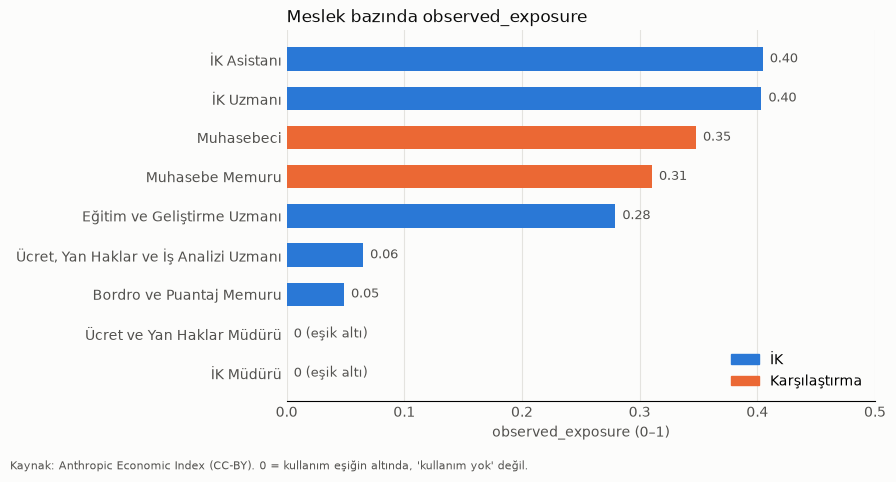

In [16]:
RENK = {"İK": "#2a78d6", "Karşılaştırma": "#eb6834"}
MUREKKEP, MUREKKEP_2, ZEMIN = "#0b0b0b", "#52514e", "#fcfcfb"

veri = meslek.sort_values("observed_exposure")
fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=ZEMIN)
ax.set_facecolor(ZEMIN)
ax.barh(veri["ad_tr"], veri["observed_exposure"], color=veri["grup"].map(RENK), height=0.6)
for y, v in enumerate(veri["observed_exposure"]):
    ax.text(v + 0.006, y, "0 (eşik altı)" if v == 0 else f"{v:.2f}", va="center", fontsize=9, color=MUREKKEP_2)

ax.set_xlim(0, max(0.5, veri["observed_exposure"].max() * 1.15))
ax.set_xlabel("observed_exposure (0–1)", color=MUREKKEP_2)
ax.set_title("Meslek bazında observed_exposure", loc="left", color=MUREKKEP, fontsize=12)
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUREKKEP_2, length=0)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in RENK.values()],
          labels=list(RENK), frameon=False, loc="lower right")
fig.text(0.01, 0.01, "Kaynak: Anthropic Economic Index (CC-BY). 0 = kullanım eşiğin altında, 'kullanım yok' değil.",
         fontsize=8, color=MUREKKEP_2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG_DIR / "observed_exposure_meslek.png", dpi=150)
plt.show()

### 8.2 · İK görevlerinin penetration dağılımı

**Bu hücre ne yapıyor:** Histogram yalnızca **penetration > 0** olan İK görevlerini gösteriyor. 0'lar
çoğunlukta olduğu için grafiğe katılırsa geri kalanı ezer, bu yüzden 0 ve eşleşmeyen sayıları
başlıkta ayrıca yazılıyor. Hiçbir görev grafikten sessizce düşmüyor.

**Neye bakın:** Grafiğin sol tarafı boş mu? Pozitif İK görevleri yüksek değerlerde toplanıyorsa, görevler
"hiç görülmedi (0)" ve "yoğun görüldü" diye ikiye ayrılıyor demektir; arada kademeli bir geçiş yok
(bkz. 2.2'deki not).

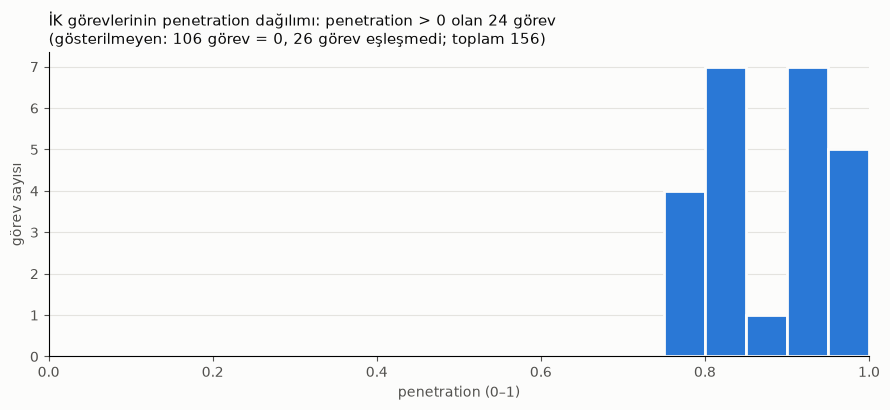

In [17]:
pozitif = ik.loc[ik["penetration"] > 0, "penetration"]
n_sifir = (ik["penetration"] == 0).sum()
n_yok = ik["penetration"].isna().sum()
assert len(pozitif) + n_sifir + n_yok == len(ik)

fig, ax = plt.subplots(figsize=(9, 4.2), facecolor=ZEMIN)
ax.set_facecolor(ZEMIN)
ax.hist(pozitif, bins=np.arange(0, 1.05, 0.05), color=RENK["İK"], edgecolor=ZEMIN, linewidth=2)
ax.set_xlim(0, 1)
ax.set_xlabel("penetration (0–1)", color=MUREKKEP_2)
ax.set_ylabel("görev sayısı", color=MUREKKEP_2)
ax.set_title(f"İK görevlerinin penetration dağılımı: penetration > 0 olan {len(pozitif)} görev\n"
             f"(gösterilmeyen: {n_sifir} görev = 0, {n_yok} görev eşleşmedi; toplam {len(ik)})",
             loc="left", color=MUREKKEP, fontsize=11)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUREKKEP_2)
fig.tight_layout()
fig.savefig(FIG_DIR / "ik_penetration_dagilimi.png", dpi=150)
plt.show()

### 8.3 · Unvan bazında görevlerin durumu

**Bu hücre ne yapıyor:** Her İK unvanının görevlerini üç gruba ayırıp yığılmış bar olarak gösteriyor:
**penetration > 0** (Claude'da görülen), **= 0** (eşik altı) ve **eşleşmedi** (bilgi yok, taralı).
Unvanlar `observed_exposure`'a göre sıralı.

**Neye bakın:** Mavi kısım her unvanda ne kadar büyük? Müdürlerde hiç mavi yok. Taralı kısım büyükse
o unvanın tablosu eksik demektir (İK Müdürü'nde 9 görev eşleşmedi).

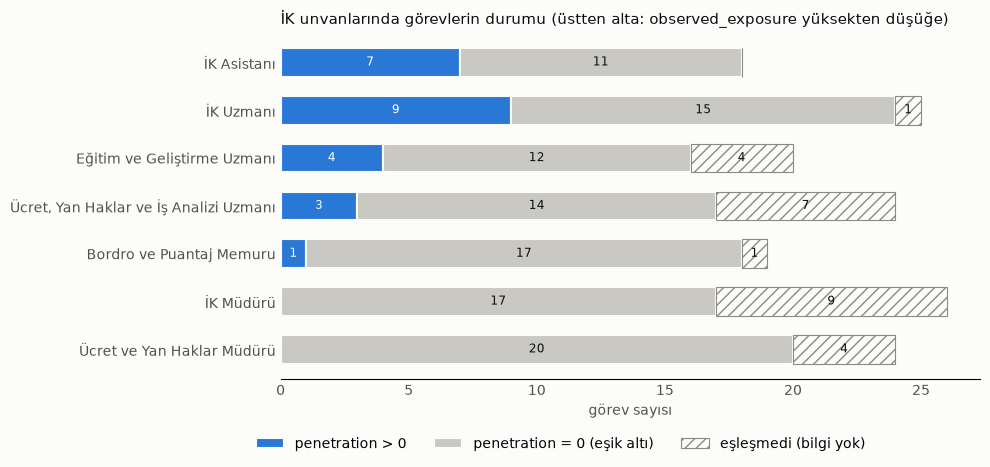

In [18]:
DURUM = [
    ("pen_pozitif", "penetration > 0", RENK["İK"], None),
    ("pen_sifir", "penetration = 0 (eşik altı)", "#c9c8c2", None),
    ("eslesmeyen", "eşleşmedi (bilgi yok)", ZEMIN, "///"),
]
v = ozet.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4.8), facecolor=ZEMIN)
ax.set_facecolor(ZEMIN)
sol = np.zeros(len(v))
for sutun, etiket, renk, desen in DURUM:
    ax.barh(v["ad_tr"], v[sutun], left=sol, height=0.6, label=etiket, color=renk, hatch=desen,
            edgecolor="#8a8984" if desen else ZEMIN, linewidth=0.8 if desen else 1.5)
    for y, (x0, n) in enumerate(zip(sol, v[sutun])):
        if n > 0:
            ax.text(x0 + n / 2, y, str(n), ha="center", va="center", fontsize=8.5,
                    color="white" if sutun == "pen_pozitif" else MUREKKEP)
    sol += v[sutun].to_numpy()

ax.set_xlabel("görev sayısı", color=MUREKKEP_2)
ax.set_title("İK unvanlarında görevlerin durumu (üstten alta: observed_exposure yüksekten düşüğe)",
             loc="left", color=MUREKKEP, fontsize=11)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUREKKEP_2, length=0)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.4, -0.13))
fig.tight_layout()
fig.savefig(FIG_DIR / "unvan_gorev_durumu.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.4 · En çok etkilenen İK görevleri: Türkçe adlar ve temalar

**Bu hücre ne yapıyor:** penetration > 0 olan her İK görevine **kısa bir Türkçe ad**, **Türkçe çeviri**
ve bir **tema** atıyor (işe alım, eğitim, bilgilendirme, belge, raporlama).

⚠️ **Çeviriler ve temalar veriden gelmiyor.** Bunları Claude, görev metinlerini okuyarak elle atadı.
Kontrol edin ve gerekirse değiştirin. Veri değişip bu listede olmayan bir pozitif görev ortaya çıkarsa
`assert` bunu söyler.

**Neye bakın:** Temalara katılıyor musunuz? Bir görev iki temaya da uyuyorsa hangisini seçerdiniz?

In [19]:
TEMALAR = ["İşe alım ve seçme", "Eğitim ve gelişim", "Çalışan bilgilendirme", "Belge ve kayıt", "Raporlama ve analiz"]
TEMA_RENK = dict(zip(TEMALAR, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

GOREV_TR = pd.DataFrame(
    [
        (18853, "Raporlama ve analiz", "İstihdam verisi analizi ve raporlama",
         "İstihdamla ilgili verileri analiz et ve gerekli raporları hazırla."),
        (103, "Eğitim ve gelişim", "Eğitim ihtiyacı analizi",
         "Eğitim ihtiyaçlarını anket, çalışan görüşmeleri, odak grupları veya yöneticiler, eğitmenler ve müşteri temsilcileriyle istişare yoluyla belirle."),
        (18862, "İşe alım ve seçme", "Aday mülakatı",
         "İş geçmişi, aldığı eğitimler, öğrenim durumu veya becerileri hakkında bilgi almak için adaylarla mülakat yap."),
        (3364, "Raporlama ve analiz", "Kurumsal ve sektörel veri analizi",
         "Kurumsal işleyişi kolaylaştırmak için kurumsal, mesleki ve sektörel verileri analiz et; işletmelere, sektöre ve kamuya teknik bilgi sağla."),
        (18865, "İşe alım ve seçme", "Nitelikli aday arama",
         "Bilgisayar veritabanları, profesyonel ağlar, internet üzerinden işe alım kaynakları, medya ilanları, iş fuarları, işe alım firmaları veya çalışan tavsiyeleri gibi kaynakları kullanarak nitelikli aday ara."),
        (2690, "İşe alım ve seçme", "Başvuruları işleme ve ön eleme",
         "Adayların nitelik ve uygunluğunu değerlendirmek için iş başvurularını işle ve incele."),
        (18874, "İşe alım ve seçme", "Seçme kriterlerini değerlendirme",
         "İşe alım ve seçme kriterlerinin mesleki, istatistiksel veya test standartlarına uygunluğunu değerlendir, gerekirse revizyon öner."),
        (18868, "İşe alım ve seçme", "Adayları pozisyonla eşleştirme",
         "Adayları iş gereklilikleriyle eşleştirmek için iş başvurularını ve personel taleplerini incele."),
        (18871, "İşe alım ve seçme", "Aday seçimi ve işe alım önerisi",
         "Nitelikli adayları seç veya yöneticilere yönlendir, uygun olduğunda işe alım önerisinde bulun."),
        (18857, "İşe alım ve seçme", "Adaylara başvuru durumunu bildirme",
         "Adaylarla iletişime geçerek başvurularının durumu hakkında bilgi ver."),
        (101, "Eğitim ve gelişim", "Eğitim materyallerini değerlendirme",
         "Eğitmenlerin hazırladığı konu başlıkları, metinler veya dağıtım notları gibi eğitim materyallerini değerlendir."),
        (18572, "Belge ve kayıt", "Personel belgelerini işleme ve saklama",
         "Kadro, işe alım, eğitim, şikâyet, performans değerlendirme, sınıflandırma ve izinlerle ilgili personel belgelerini işle, doğrula ve sakla."),
        (2523, "Çalışan bilgilendirme", "Bordro, vergi ve yan hak bilgilendirmesi",
         "Çalışanlara ve yöneticilere bordro, vergi, yan hak planları ve toplu sözleşme hükümleri hakkında bilgi ver."),
        (20475, "Eğitim ve gelişim", "Eğitim kılavuzu ve materyali hazırlama",
         "Eğitim prosedür kılavuzları, rehberler veya dağıtım notları ve görsel materyaller gibi ders içeriklerini temin et, düzenle veya geliştir."),
        (2691, "Çalışan bilgilendirme", "Maaş, yan hak vb. soruları yanıtlama",
         "Sınavlar, uygunluk, maaşlar, yan haklar ve ilgili diğer konulardaki soruları yanıtla."),
        (20474, "Eğitim ve gelişim", "Oryantasyon ve eğitim programı tasarımı",
         "Çalışanlar veya müşteriler için oryantasyon ve eğitim programları tasarla, planla, düzenle veya yönet."),
        (3372, "Raporlama ve analiz", "Araştırma sonuçlarını yayına hazırlama",
         "Araştırma sonuçlarını dergi, kitap, kılavuz ve film biçiminde yayına hazırla."),
        (3369, "Eğitim ve gelişim", "Müfredat ve eğitim materyali geliştirme",
         "Eğitim programları için müfredat ve materyalleri planla, geliştir ve eğitimi yürüt."),
        (18863, "Belge ve kayıt", "İK belgelerini güncel tutma",
         "Organizasyon şemaları, çalışan el kitapları, rehberler veya performans değerlendirme formları gibi İK belgelerini güncel tut."),
        (2701, "İşe alım ve seçme", "İş ilanı yayımlama",
         "Açık pozisyonların ilan edilmesini sağla ve uygun çalışanları pozisyonlardan haberdar et."),
        (2687, "Çalışan bilgilendirme", "Personel politikalarını açıklama",
         "Şirketin personel politikalarını, yan haklarını ve prosedürlerini çalışanlara veya adaylara açıkla."),
        (2698, "İşe alım ve seçme", "Adaylara kabul/ret bildirme",
         "Adaylara işe kabul veya ret kararını bildir."),
        (18861, "Çalışan bilgilendirme", "İK politika ve mevzuatını yorumlama",
         "İK politikalarını, prosedürlerini, yasaları, standartları veya düzenlemeleri yorumla ve açıkla."),
        (2697, "Belge ve kayıt", "Personel raporları derleme",
         "Personel faaliyetleriyle ilgili rapor ve belgeleri derle ve hazırla."),
    ],
    columns=["Task ID", "tema", "kisa_ad", "gorev_tr"],
)
assert GOREV_TR["Task ID"].is_unique and GOREV_TR["tema"].isin(TEMALAR).all()

once = (ik["penetration"] > 0).sum()
etkilenen = (ik[ik["penetration"] > 0]
             .merge(GOREV_TR, on="Task ID", how="left", validate="one_to_one")
             .sort_values(["penetration", "Task ID"], ascending=[False, True])
             .reset_index(drop=True))
log("penetration > 0 olan İK görevleri + Türkçe ad/tema", once, len(etkilenen))
temasiz = etkilenen.loc[etkilenen["tema"].isna(), "Task ID"].tolist()
assert not temasiz, f"Türkçe adı/teması atanmamış pozitif görev(ler): {temasiz}. GOREV_TR'ye ekleyin."
fazla = set(GOREV_TR["Task ID"]) - set(etkilenen["Task ID"])
assert not fazla, f"GOREV_TR'de olup artık pozitif olmayan görev(ler): {fazla}"

display(etkilenen[["ad_tr", "gorev_turu", "penetration", "tema", "kisa_ad", "gorev_tr"]])

[penetration > 0 olan İK görevleri + Türkçe ad/tema] önce: 24 satır → sonra: 24 satır (fark: +0)


,ad_tr,gorev_turu,penetration,tema,kisa_ad,gorev_tr
0,Eğitim ve Geliştirme Uzmanı,Core,1.0000,Eğitim ve gelişim,Eğitim ihtiyacı analizi,"Eğitim ihtiyaçlarını anket, çalışan görüşmeleri, odak grupları veya yöneticiler, eğitmenler ve müşteri temsilcileriyle istişare yoluyla ..."
1,İK Uzmanı,Core,1.0000,Raporlama ve analiz,İstihdam verisi analizi ve raporlama,İstihdamla ilgili verileri analiz et ve gerekli raporları hazırla.
2,İK Uzmanı,Core,0.9780,İşe alım ve seçme,Aday mülakatı,"İş geçmişi, aldığı eğitimler, öğrenim durumu veya becerileri hakkında bilgi almak için adaylarla mülakat yap."
3,"Ücret, Yan Haklar ve İş Analizi Uzmanı",Supplemental,0.9764,Raporlama ve analiz,Kurumsal ve sektörel veri analizi,"Kurumsal işleyişi kolaylaştırmak için kurumsal, mesleki ve sektörel verileri analiz et; işletmelere, sektöre ve kamuya teknik bilgi sağla."
4,İK Uzmanı,Core,0.9758,İşe alım ve seçme,Nitelikli aday arama,"Bilgisayar veritabanları, profesyonel ağlar, internet üzerinden işe alım kaynakları, medya ilanları, iş fuarları, işe alım firmaları veya çalışan tavsiyeleri gibi kaynakları kullanarak nitelikli aday ara."
5,İK Asistanı,Supplemental,0.9456,İşe alım ve seçme,Başvuruları işleme ve ön eleme,Adayların nitelik ve uygunluğunu değerlendirmek için iş başvurularını işle ve incele.
6,İK Uzmanı,Supplemental,0.9414,İşe alım ve seçme,Seçme kriterlerini değerlendirme,"İşe alım ve seçme kriterlerinin mesleki, istatistiksel veya test standartlarına uygunluğunu değerlendir, gerekirse revizyon öner."
7,İK Uzmanı,Core,0.9369,İşe alım ve seçme,Adayları pozisyonla eşleştirme,Adayları iş gereklilikleriyle eşleştirmek için iş başvurularını ve personel taleplerini incele.
8,İK Uzmanı,Core,0.9296,İşe alım ve seçme,Aday seçimi ve işe alım önerisi,"Nitelikli adayları seç veya yöneticilere yönlendir, uygun olduğunda işe alım önerisinde bulun."
9,İK Uzmanı,Core,0.9100,İşe alım ve seçme,Adaylara başvuru durumunu bildirme,Adaylarla iletişime geçerek başvurularının durumu hakkında bilgi ver.


### 8.5 · Grafik: en çok etkilenen İK görevleri

**Bu hücre ne yapıyor:** penetration > 0 olan tüm İK görevlerini yatay bar olarak gösteriyor. Etikette
görevin kısa Türkçe adı ve unvanı yazıyor, renk temayı gösteriyor.

**Neye bakın:** Hangi tema listeye hâkim? En üstteki görevler hangi unvanlara ait?
Barların hepsi 0,75'in üstünde. Bu bölümde değer farklarından çok **listede hangi görevlerin
bulunduğu** önemli (bkz. 2.2'deki "bayrak" notu).

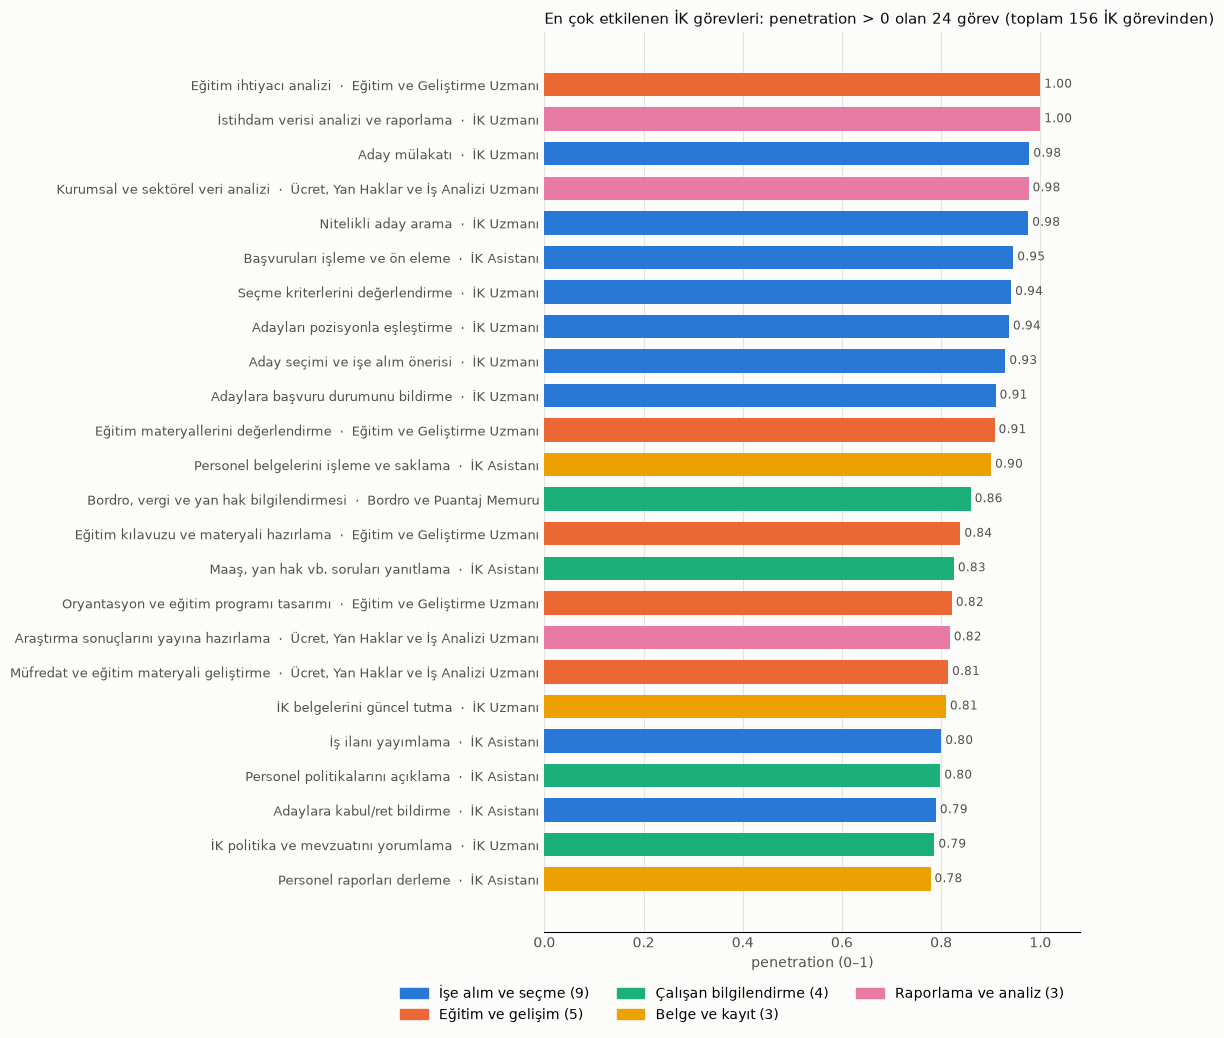

In [20]:
v = etkilenen.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 0.36 * len(v) + 1.8), facecolor=ZEMIN)
ax.set_facecolor(ZEMIN)
ax.barh(range(len(v)), v["penetration"], color=v["tema"].map(TEMA_RENK), height=0.68)
ax.set_yticks(range(len(v)), [f"{k}  ·  {m}" for k, m in zip(v["kisa_ad"], v["ad_tr"])], fontsize=9)
for y, p in enumerate(v["penetration"]):
    ax.text(p + 0.008, y, f"{p:.2f}", va="center", fontsize=8.5, color=MUREKKEP_2)

ax.set_xlim(0, 1.08)
ax.set_xlabel("penetration (0–1)", color=MUREKKEP_2)
ax.set_title(f"En çok etkilenen İK görevleri: penetration > 0 olan {len(v)} görev (toplam {len(ik)} İK görevinden)",
             loc="left", color=MUREKKEP, fontsize=11)
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUREKKEP_2, length=0)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=TEMA_RENK[t]) for t in TEMALAR],
          labels=[f"{t} ({(etkilenen['tema'] == t).sum()})" for t in TEMALAR],
          frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.35, -0.045))
fig.tight_layout()
fig.savefig(FIG_DIR / "en_cok_etkilenen_gorevler.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.6 · Grafik: unvan × tema

**Bu hücre ne yapıyor:** Her unvanın pozitif görevlerinin hangi temalara dağıldığını yığılmış bar olarak
gösteriyor, yanına Core/Supplemental kırılımını tablo olarak ekliyor.

**Neye bakın:** İK Uzmanı ve İK Asistanı'nda işe alım baskın mı? Ücret, Yan Haklar ve İş Analizi
Uzmanı'nın pozitif görevleri Core mu, Supplemental mı? Supplemental görevler zamanın küçük bir kısmını
aldığı için, zaman ağırlıklı `observed_exposure` skorunu az yükseltir.

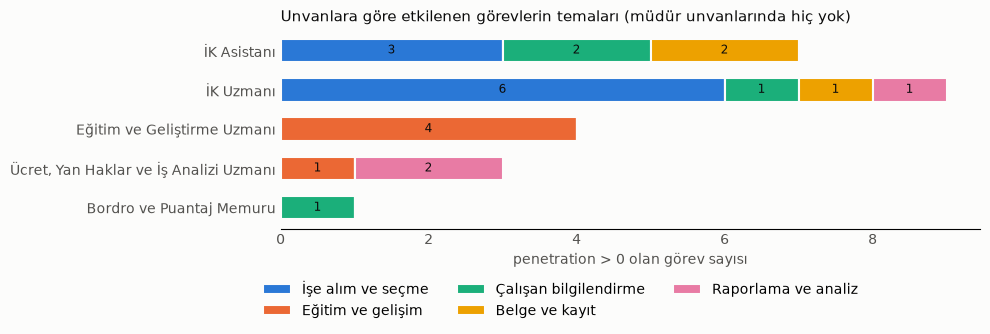

gorev_turu,Core,Supplemental,Toplam
ad_tr,,,
Bordro ve Puantaj Memuru,1,0,1
Eğitim ve Geliştirme Uzmanı,4,0,4
"Ücret, Yan Haklar ve İş Analizi Uzmanı",0,3,3
İK Asistanı,4,3,7
İK Uzmanı,8,1,9
Toplam,17,7,24


In [21]:
sira = [a for a in ozet["ad_tr"] if a in set(etkilenen["ad_tr"])][::-1]
tablo = pd.crosstab(etkilenen["ad_tr"], etkilenen["tema"]).reindex(index=sira, columns=TEMALAR, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3.6), facecolor=ZEMIN)
ax.set_facecolor(ZEMIN)
sol = np.zeros(len(tablo))
for t in TEMALAR:
    ax.barh(tablo.index, tablo[t], left=sol, color=TEMA_RENK[t], height=0.6, label=t, edgecolor=ZEMIN, linewidth=1.5)
    for y, (x0, n) in enumerate(zip(sol, tablo[t])):
        if n > 0:
            ax.text(x0 + n / 2, y, str(n), ha="center", va="center", fontsize=8.5, color=MUREKKEP)
    sol += tablo[t].to_numpy()
ax.set_xlabel("penetration > 0 olan görev sayısı", color=MUREKKEP_2)
ax.set_title("Unvanlara göre etkilenen görevlerin temaları (müdür unvanlarında hiç yok)", loc="left", color=MUREKKEP, fontsize=11)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUREKKEP_2, length=0)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.4, -0.2))
fig.tight_layout()
fig.savefig(FIG_DIR / "unvan_tema.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.crosstab(etkilenen["ad_tr"], etkilenen["gorev_turu"], margins=True, margins_name="Toplam"))

## 9 · Excel'e kaydet: `reports/tables/ik_gorevleri.xlsx`

**Bu hücre ne yapıyor:** Tüm İK görevlerini (eşleşmeyenler dahil) Türkçe sütun adlarıyla Excel'e yazıyor.
Sona boş bir **"Benim yorumum"** sütunu ekliyor. İkinci sayfa (`aciklama`) sütun tanımlarını içeriyor.
Başlık satırı donduruluyor. Dosya geri okunup satır sayısı doğrulanıyor.

**Neye bakın:** Excel'de `penetration` hücresi **boş** ise görev eşleşmemiştir; **0** ise eşleşmiş ama
eşiğin altında kalmıştır. İkisini karıştırmayın.

⚠️ Bu hücre her çalıştığında dosyanın **üzerine yazar**. Kendi notlarınızı ekledikten sonra dosyayı
farklı bir adla kaydedin (ör. `ik_gorevleri_notlarim.xlsx`).

In [22]:
excel = (
    ik.sort_values(["observed_exposure", "occ_code", "penetration", "Task ID"],
                   ascending=[False, True, False, True], na_position="last")
    [["occ_code", "ad_tr", "ad_en", "O*NET-SOC Code", "Task ID", "gorev_turu", "Task",
      "penetration", "eslesme", "observed_exposure"]]
    .rename(columns={
        "occ_code": "Meslek kodu", "ad_tr": "Meslek (TR)", "ad_en": "Meslek (EN)",
        "O*NET-SOC Code": "O*NET kodu", "Task ID": "Görev ID", "gorev_turu": "Görev türü",
        "Task": "Görev", "penetration": "penetration", "eslesme": "Eşleşme",
        "observed_exposure": "Meslek observed_exposure",
    })
    .assign(**{"Benim yorumum": ""})
)
assert len(excel) == len(ik)

aciklama = pd.DataFrame(
    [
        ("Görev türü", "Core = asıl görev, Supplemental = ek görev, Belirtilmemiş = O*NET'te boş"),
        ("penetration", "Görevin Claude iş kullanımında kapsanma derecesi (0–1). 0 = eşiğin altında, 'kullanım yok' değil. Boş = eşleşmedi."),
        ("Eşleşme", "Görev metni (strip + lower) task_penetration'da bulundu mu"),
        ("Meslek observed_exposure", "Meslek düzeyi, zaman ağırlıklı kapsama (0–1)"),
        ("Kaynak", "Anthropic Economic Index (Hugging Face, CC-BY); https://www.anthropic.com/research/labor-market-impacts"),
    ],
    columns=["Sütun", "Açıklama"],
)

yol = TABLE_DIR / "ik_gorevleri.xlsx"
with pd.ExcelWriter(yol, engine="openpyxl") as w:
    excel.to_excel(w, sheet_name="ik_gorevleri", index=False)
    aciklama.to_excel(w, sheet_name="aciklama", index=False)
    ws = w.sheets["ik_gorevleri"]
    ws.freeze_panes = "A2"
    for harf, genislik in zip("ABCDEFGHIJK", [11, 30, 40, 12, 9, 13, 90, 12, 11, 14, 40]):
        ws.column_dimensions[harf].width = genislik
    w.sheets["aciklama"].column_dimensions["A"].width = 26
    w.sheets["aciklama"].column_dimensions["B"].width = 110

geri = pd.read_excel(yol, sheet_name="ik_gorevleri")
assert len(geri) == len(excel) and list(geri.columns) == list(excel.columns)
print(f"Kaydedildi: {yol.relative_to(ROOT).as_posix()}  ({len(geri)} satır, {geri.shape[1]} sütun)")

Kaydedildi: reports/tables/ik_gorevleri.xlsx  (156 satır, 11 sütun)


## 10 · Öne çıkan bulgular

Bu bölüm notebook'un sayılarını tek yerde topluyor. Hepsi **betimleyici**: ne görüldüğünü söylüyor,
neden görüldüğünü kanıtlamıyor. Okurken iki şeyi akılda tutun:
**0 = eşik altı (hiç kullanılmıyor değil)** ve **veri yalnızca Claude kullanımını kapsıyor.**

### 10.1 · Unvan sıralaması

**Bu hücre ne yapıyor:** 9 unvanı `observed_exposure`'a göre sıralıyor ve İK unvanları için pozitif görev
sayısını ve oranını ekliyor.

**Neye bakın:** İK unvanları kendi içinde ikiye ayrılıyor. Bazıları muhasebe mesleklerinin üstünde,
bazıları sıfıra yakın.

In [23]:
unvan = meslek.merge(
    ozet[["occ_code", "gorev", "pen_pozitif", "pen_sifir", "eslesmeyen"]], on="occ_code", how="left", validate="one_to_one"
)
unvan["pozitif_oran"] = (unvan["pen_pozitif"] / unvan["gorev"]).round(2)
unvan.insert(0, "sira", range(1, len(unvan) + 1))
display(unvan[["sira", "ad_tr", "ad_en", "grup", "observed_exposure", "gorev", "pen_pozitif", "pozitif_oran", "pen_sifir", "eslesmeyen"]])
print("Not: Karşılaştırma meslekleri için görev düzeyi sayımlar yapılmadı (boş).")

,sira,ad_tr,ad_en,grup,observed_exposure,gorev,pen_pozitif,pozitif_oran,pen_sifir,eslesmeyen
0,1,İK Asistanı,"Human Resources Assistants, Except Payroll and Timekeeping",İK,0.4046,18.0,7.0,0.39,11.0,0.0
1,2,İK Uzmanı,Human Resources Specialists,İK,0.4034,25.0,9.0,0.36,15.0,1.0
2,3,Muhasebeci,Accountants and Auditors,Karşılaştırma,0.3478,NaN,NaN,NaN,NaN,NaN
3,4,Muhasebe Memuru,"Bookkeeping, Accounting, and Auditing Clerks",Karşılaştırma,0.3104,NaN,NaN,NaN,NaN,NaN
4,5,Eğitim ve Geliştirme Uzmanı,Training and Development Specialists,İK,0.2793,20.0,4.0,0.20,12.0,4.0
5,6,"Ücret, Yan Haklar ve İş Analizi Uzmanı","Compensation, Benefits, and Job Analysis Specialists",İK,0.0649,24.0,3.0,0.12,14.0,7.0
6,7,Bordro ve Puantaj Memuru,Payroll and Timekeeping Clerks,İK,0.0487,19.0,1.0,0.05,17.0,1.0
7,8,İK Müdürü,Human Resources Managers,İK,0.0000,26.0,0.0,0.00,17.0,9.0
8,9,Ücret ve Yan Haklar Müdürü,Compensation and Benefits Managers,İK,0.0000,24.0,0.0,0.00,20.0,4.0


Not: Karşılaştırma meslekleri için görev düzeyi sayımlar yapılmadı (boş).


### 10.2 · Aynı iş, farklı unvan

**Bu hücre ne yapıyor:** Görev metninde işe alım kelimeleri geçen (recruit, interview, applicant,
candidate, vacanc, hiring) tüm İK görevlerini unvanlarıyla birlikte gösteriyor. Ardından eğitim
ihtiyacı analizi görevlerini ayrıca listeliyor.

**Neye bakın:** Benzer işler uzman ve asistan unvanlarında yüksek değer alıyor. Müdür unvanlarında
ise 0 ya da eşleşmemiş. Olası nedenler (bunlar varsayım, kanıt değil):
1. Makaleye göre birbirine çok benzeyen görevlerde kullanım sayıları **aralarında bölünüyor**. Müdürün
   görevi bölünen payla eşiğin altında kalmış olabilir.
2. Müdür görevleri daha genel ve yönetsel yazılmış ("plan, direct, coordinate"), bu yüzden konuşmalarla
   daha zor eşleşiyor olabilir.
3. Bazı müdür görevleri hiç eşleşmedi (bkz. 5.4), bu yüzden bilgi yok.

In [24]:
ise_alim = ik[ik["Task"].str.contains(r"recruit|interview|applicant|candidate|vacanc|hiring", case=False, regex=True)]
print(f"İşe alım kelimesi geçen İK görevi: {len(ise_alim)}")
display(ise_alim.groupby("ad_tr").agg(
    gorev=("Task", "size"),
    pen_pozitif=("penetration", lambda s: (s > 0).sum()),
    pen_sifir=("penetration", lambda s: (s == 0).sum()),
    eslesmeyen=("penetration", lambda s: s.isna().sum()),
).sort_values("pen_pozitif", ascending=False))
display(ise_alim.sort_values(["ad_tr", "penetration"], ascending=[True, False], na_position="last")
        [["ad_tr", "penetration", "eslesme", "Task"]].reset_index(drop=True))

print("\nEğitim ihtiyacı analizi görevleri:")
display(ik[ik["Task"].str.contains(r"training needs", case=False)][["ad_tr", "penetration", "eslesme", "Task"]].reset_index(drop=True))

İşe alım kelimesi geçen İK görevi: 32


,gorev,pen_pozitif,pen_sifir,eslesmeyen
ad_tr,,,,
İK Uzmanı,15,6,8,1
İK Asistanı,9,5,4,0
Eğitim ve Geliştirme Uzmanı,2,1,1,0
Ücret ve Yan Haklar Müdürü,2,0,2,0
"Ücret, Yan Haklar ve İş Analizi Uzmanı",1,0,1,0
İK Müdürü,3,0,1,2


,ad_tr,penetration,eslesme,Task
0,Eğitim ve Geliştirme Uzmanı,1.0000,Eşleşti,"Assess training needs through surveys, interviews with employees, focus groups, or consultation with managers, instructors, or customer ..."
1,Eğitim ve Geliştirme Uzmanı,0.0000,Eşleşti,Coordinate recruitment and placement of training program participants.
2,Ücret ve Yan Haklar Müdürü,0.0000,Eşleşti,"Formulate policies, procedures and programs for recruitment, testing, placement, classification, orientation, benefits and compensation,..."
3,Ücret ve Yan Haklar Müdürü,0.0000,Eşleşti,Conduct exit interviews to identify reasons for employee termination.
4,"Ücret, Yan Haklar ve İş Analizi Uzmanı",0.0000,Eşleşti,"Observe, interview, and survey employees and conduct focus group meetings to collect job, organizational, and occupational information."
5,İK Asistanı,0.9456,Eşleşti,Process and review employment applications to evaluate qualifications or eligibility of applicants.
6,İK Asistanı,0.9009,Eşleşti,"Process, verify, and maintain personnel related documentation, including staffing, recruitment, training, grievances, performance evalua..."
7,İK Asistanı,0.8005,Eşleşti,Arrange for advertising or posting of job vacancies and notify eligible workers of position availability.
8,İK Asistanı,0.7985,Eşleşti,"Explain company personnel policies, benefits, and procedures to employees or job applicants."
9,İK Asistanı,0.7895,Eşleşti,Inform job applicants of their acceptance or rejection of employment.



Eğitim ihtiyacı analizi görevleri:


,ad_tr,penetration,eslesme,Task
0,İK Müdürü,NaN,Eşleşmedi,"Analyze training needs to design employee development, language training and health and safety programs."
1,Eğitim ve Geliştirme Uzmanı,1.0,Eşleşti,"Assess training needs through surveys, interviews with employees, focus groups, or consultation with managers, instructors, or customer ..."


### 10.3 · En çok etkilenen görevler tablosu (Excel)

**Bu hücre ne yapıyor:** 8.4'teki tabloyu (pozitif görevler, Türkçe ad ve çeviri, tema) ayrı bir Excel
dosyasına yazıyor: `reports/tables/en_cok_etkilenen_gorevler.xlsx`. `ik_gorevleri.xlsx` dosyasına
dokunmuyor. Dosya geri okunup satır sayısı doğrulanıyor.

In [25]:
etk_excel = etkilenen[["ad_tr", "ad_en", "Task ID", "gorev_turu", "penetration", "tema", "kisa_ad", "gorev_tr", "Task"]].rename(columns={
    "ad_tr": "Unvan (TR)", "ad_en": "Unvan (EN)", "Task ID": "Görev ID", "gorev_turu": "Görev türü",
    "tema": "Tema (Claude ataması)", "kisa_ad": "Kısa ad", "gorev_tr": "Görev (TR, Claude çevirisi)", "Task": "Görev (EN, O*NET)",
})
yol2 = TABLE_DIR / "en_cok_etkilenen_gorevler.xlsx"
with pd.ExcelWriter(yol2, engine="openpyxl") as w:
    etk_excel.to_excel(w, sheet_name="etkilenen_gorevler", index=False)
    ws = w.sheets["etkilenen_gorevler"]
    ws.freeze_panes = "A2"
    for harf, genislik in zip("ABCDEFGHI", [30, 40, 9, 13, 12, 22, 38, 80, 80]):
        ws.column_dimensions[harf].width = genislik
geri = pd.read_excel(yol2)
assert len(geri) == len(etk_excel)
print(f"Kaydedildi: {yol2.relative_to(ROOT).as_posix()}  ({len(geri)} satır)")

Kaydedildi: reports/tables/en_cok_etkilenen_gorevler.xlsx  (24 satır)


### 10.4 · Özet: bulgular

Aşağıdaki sayılar yukarıdaki çıktılardan alındı (Kasım 2026'da indirilen veri sürümü).

**1. İK unvanları ikiye ayrılıyor.**
- **İK Asistanı (0,40)** ve **İK Uzmanı (0,40)**, karşılaştırma meslekleri Muhasebeci (0,35) ve Muhasebe
  Memuru'nun (0,31) bile üstünde. **Eğitim ve Geliştirme Uzmanı (0,28)** onlara yakın.
- **Ücret, Yan Haklar ve İş Analizi Uzmanı (0,06)** ve **Bordro ve Puantaj Memuru (0,05)** düşük.
- **İK Müdürü** ve **Ücret ve Yan Haklar Müdürü** 0'da, yani eşiğin altında.

**2. Etkilenen görevler az ama belirgin.** 156 İK görevinin yalnızca **24'ü (%15)** 0'dan büyük. 106 görev 0,
26 görev eşleşmedi. Bir görev Claude'da görüldüğünde değeri hep yüksek (0,78–1,00).

**3. En çok etkilenen iş alanı: işe alım ve seçme.** 24 pozitif görevin **9'u** işe alımla ilgili: aday
arama, başvuru ön eleme, mülakat, adayı pozisyonla eşleştirme, işe alım önerisi, kabul/ret bildirme.
Sonra **eğitim ve gelişim (5)**, **çalışan bilgilendirme (4)**, **belge ve kayıt (3)** ve **raporlama ve analiz (3)** geliyor.

**4. En yüksek değerli görevler:**
| Görev | Unvan | penetration |
|---|---|---|
| İstihdam verisi analizi ve raporlama | İK Uzmanı | 1,00 |
| Eğitim ihtiyacı analizi | Eğitim ve Geliştirme Uzmanı | 1,00 |
| Aday mülakatı | İK Uzmanı | 0,98 |
| Kurumsal ve sektörel veri analizi | Ücret, Yan Haklar ve İş Analizi Uzmanı | 0,98 |
| Nitelikli aday arama | İK Uzmanı | 0,98 |
| Başvuruları işleme ve ön eleme | İK Asistanı | 0,95 |

**5. Unvan bazında:** İK Uzmanı'nda 9 pozitif görev var (8'i Core). İK Asistanı'nda 7, Eğitim ve
Geliştirme Uzmanı'nda 4 (hepsi Core). Ücret, Yan Haklar ve İş Analizi Uzmanı'nda 3 pozitif görev var ve
**3'ü de Supplemental**. Yani eşleşen Core görevlerinin hiçbiri Claude'da görülmüyor (7 görev de
eşleşmedi), düşük skorun açıklaması büyük olasılıkla bu. Bordro Memuru'nda yalnızca 1 görev pozitif ("bordro, vergi ve yan
hak bilgilendirmesi"). Bordro hesaplama ve işleme görevlerinin hepsi 0.

**6. Aynı iş, farklı unvan.** İşe alım, raporlama ve eğitim ihtiyacı analizi gibi işler uzman ve asistan
unvanlarında 0,8–1,0 arası değer alıyor. Müdür unvanlarındaki benzer görevler ise 0 ya da eşleşmemiş.
Bu fark gerçek bir kullanım farkı olabilir, ama ölçüm yönteminin bir sonucu da olabilir (bkz. 10.2).
"Müdürler etkilenmiyor" sonucuna varmak için erken.

> Bu bulgular meslek ve görev düzeyindedir. Bireyler veya belirli çalışanlar hakkında yargıya
> dönüştürülmez, "işten çıkarma riski" olarak sunulmaz.

## 11 · Neyi henüz bilmiyoruz?

Bu notebook'tan sonra açık kalan sorular. Her biri ileride bir karar ya da yeni bir veri kaynağı gerektiriyor.

1. **Eşik nedir?** 0, "minimum kullanım eşiğinin altında" demek, ama eşiğin değeri yayımlanmamış.
   0'ların ne kadarı gerçekten seyrek kullanım, ne kadarı örneklemin dışında kalan nadir görevler?
   İlgili gözlem: pozitif değerler 0,50'den başlıyor, yani 0 ile 0,50 arası boş. Değer, eşiği geçen
   görevler için mi hesaplanıyor ve geri kalanı 0'a mı sabitleniyor? 0,5 civarı değerler yalnızca
   "destekleyici kullanım = yarım ağırlık" kuralından mı geliyor?
2. **İki tür 0'ı ayırabilir miyiz?** Bir görev, LLM'in teorik olarak hızlandıramadığı (β = 0) bir görev
   olduğu için de 0 olabilir, eşiğin altında kaldığı için de. β değerleri (Eloundou vd. 2023) bu dosyalarda yok.
3. **Meslek skoru görevlerden nasıl hesaplanıyor?** `observed_exposure` zaman ağırlıklı. Görev başına
   zaman payları elimizde yok. Bu yüzden görev tablosundan meslek skorunu yeniden üretemiyoruz
   (Bölüm 6.1'deki ağırlıksız ortalama ile karşılaştırın).
4. **Müdürler neden 0?** İK Müdürü ve Ücret Müdürü 0, uzman ve asistanlar ise yüksek. Bu gerçekten
   kullanım farkı mı, görev metinlerinin yönetsel ve genel olması mı, yoksa eşleşme kaybı mı?
   (Bölüm 5.2'de bu mesleklerde eşleşmeyen görev sayısına bakın.)
5. **Eşleşmeyen görevler ne olacak?** Teşhis tablosu (5.4) farkların çoğunun noktalama veya sürüm farkı
   olabileceğini gösteriyor. Bulanık eşleştirme yapılmalı mı? Yapılırsa hangi eşikle, ve yanlış
   eşleşmeler nasıl denetlenecek?
6. **Hangi O*NET sürümü?** `task_penetration` metinleri hangi O*NET sürümünden geliyor? Görev tablosu
   `release_2025_02_10` içinde ve görev bilgilerinin güncellenme tarihleri 2003–2015 arasında.
7. **Yalnızca Claude.** Veri, Claude (ve yalnızca örneklenen trafik) kullanımını yansıtıyor. Diğer
   yapay zekâ araçları ve İK yazılımlarına gömülü otomasyon (bordro sistemleri, ATS) bu veride görünmüyor.
8. **Otomasyon mu, destek mi?** Penetration, tam otomasyon ile destekleyici kullanımı tek bir sayıda
   birleştiriyor. İK görevlerinde hangisi baskın? (Ayrı bir notebook için aday.)
9. **Zaman.** Elimizdeki tek bir kesit. Bu değerler zaman içinde nasıl değişiyor? (Ayrı bir notebook için aday.)
10. **Türkiye bağlamı.** O*NET ABD meslek tanımları. Türkiye'deki İK rollerinin görev dağılımı farklı olabilir.

> Hatırlatma: Bu veriler meslek ve görev düzeyindedir. Bulgular bireyler veya belirli çalışanlar hakkında
> yargıya dönüştürülmez.